# Routing method comparison: quality metrics

`return_ops_all_methods` collects routed SWAP counts, optimized two-qubit gate counts, and circuit depth. Its results are cached beside this notebook so plotting can be rerun without repeating the long benchmark.


## Imports and backend

In [14]:
from helper_functions import (
    return_ops_all_methods,
    return_times_all_methods,
    plot_metric_results,
)
from qiskit_ibm_runtime.fake_provider import FakeMarrakesh
from IPython.display import display
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

backend = FakeMarrakesh()

## Experiment configuration

In [15]:
k_list = [2, 3, 4]
average_over = 5
reps = 1
opt_level = 1

# Keep the graph sizes and parameter ranges comparable to comparison_plots_final.ipynb.
nodes_reg = list(range(10, 151, 2))
params_reg = list(range(3, 9))
nodes_ba = list(range(6, 151, 2))
params_ba = list(range(2, 5))

## Collect or load quality metrics

Each `return_ops_all_methods` result is cached in a JSON file beside this notebook. The first run (or a forced recomputation) runs the benchmark; later runs load the saved data so plot edits do not repeat the long compilation sweep. Results are checkpointed after each graph parameter.


In [3]:
import json
from pathlib import Path

# Store the cache beside submissions/helper_functions.py whether Jupyter was
# launched from the repository root or from the submissions directory.
_cache_dir = Path.cwd()
if not (_cache_dir / 'helper_functions.py').is_file() and (_cache_dir / 'submissions' / 'helper_functions.py').is_file():
    _cache_dir = _cache_dir / 'submissions'
OPS_RESULTS_FILE = _cache_dir / 'comparison_plots_revision_copy_ops_results.json'

# Set True to recompute and replace all cached results. Leave False for plot-only reruns.
# If only plot styling changes, leave the experiment configuration untouched.
RECOMPUTE_OPS_RESULTS = True
experiment_config = {
    'average_over': int(average_over),
    'reps': int(reps),
    'opt_level': int(opt_level),
    'k_list': list(k_list),
    'nodes_reg': list(nodes_reg),
    'params_reg': list(params_reg),
    'nodes_ba': list(nodes_ba),
    'params_ba': list(params_ba),
    'noise_aware': True,
}

_memory_results_reg = globals().get('results_reg')
_memory_results_ba = globals().get('results_ba')
_expected_methods = ['SABRE', 'Trivial', 'FOM'] + [f'SAM{k}' for k in k_list]


def _results_match_current_shape(results, params, node_list):
    """Check whether an existing in-memory result covers this sweep's shape/methods."""
    if not isinstance(results, dict):
        return False
    for param in params:
        entry = results.get(param, results.get(str(param)))
        if not isinstance(entry, dict):
            return False
        for metric in ('swaps', 'two_qubit_gates'):
            statistics = entry.get(metric, {})
            means = statistics.get('means', {})
            if set(means) != set(_expected_methods):
                return False
            if any(len(means[method]) != len(node_list) for method in _expected_methods):
                return False
    return True


_cache_from_memory = False
if OPS_RESULTS_FILE.exists() and not RECOMPUTE_OPS_RESULTS:
    _ops_payload = json.loads(OPS_RESULTS_FILE.read_text(encoding='utf-8'))
    if _ops_payload.get('configuration') != experiment_config:
        raise ValueError(
            f'{OPS_RESULTS_FILE.name} was created with a different experiment configuration. '
            'Set RECOMPUTE_OPS_RESULTS = True to run and save the current configuration.'
        )
    results_reg = {
        int(param): values for param, values in _ops_payload.get('results_reg', {}).items()
    }
    results_ba = {
        int(param): values for param, values in _ops_payload.get('results_ba', {}).items()
    }
    print(f'Loaded cached quality results from {OPS_RESULTS_FILE}')
elif (
    not RECOMPUTE_OPS_RESULTS
    and _results_match_current_shape(_memory_results_reg, params_reg, nodes_reg)
    and _results_match_current_shape(_memory_results_ba, params_ba, nodes_ba)
):
    # Preserve results from a long run performed earlier in this same kernel session.
    results_reg = {int(param): value for param, value in _memory_results_reg.items()}
    results_ba = {int(param): value for param, value in _memory_results_ba.items()}
    _cache_from_memory = True
    print('Reusing completed in-memory results and writing them to the JSON cache.')
else:
    results_reg = {}
    results_ba = {}
    if OPS_RESULTS_FILE.exists() and RECOMPUTE_OPS_RESULTS:
        print('Recomputing all quality results and replacing the existing cache.')
    else:
        print('No compatible cache found; running the benchmark and saving checkpoints.')


def save_ops_checkpoint():
    payload = {
        'configuration': experiment_config,
        'results_reg': results_reg,
        'results_ba': results_ba,
    }
    OPS_RESULTS_FILE.write_text(
        json.dumps(payload, indent=2, ensure_ascii=False),
        encoding='utf-8',
    )


if _cache_from_memory:
    save_ops_checkpoint()


for param in params_reg:
    if param in results_reg:
        print(f'Using cached random-regular results for parameter {param}.')
        continue
    results_reg[param] = return_ops_all_methods(
        backend,
        graph_type='reg',
        param=param,
        average_over=average_over,
        node_list=nodes_reg,
        k_list=k_list,
        reps=reps,
        opt_level=opt_level,
        noise_aware=True,
    )
    save_ops_checkpoint()

for param in params_ba:
    if param in results_ba:
        print(f'Using cached Barabasi-Albert results for parameter {param}.')
        continue
    results_ba[param] = return_ops_all_methods(
        backend,
        graph_type='ba',
        param=param,
        average_over=average_over,
        node_list=nodes_ba,
        k_list=k_list,
        reps=reps,
        opt_level=opt_level,
        noise_aware=True,
    )
    save_ops_checkpoint()

print(f'Quality results saved to {OPS_RESULTS_FILE}')


No compatible cache found; running the benchmark and saving checkpoints.


Quality results saved to c:\Users\devra\Projects\Qubit Routing\submissions\comparison_plots_revision_copy_ops_results.json


## Tables of collected values

Each cell reports the mean and standard deviation across repeated runs as `mean ± std`.

In [4]:
def metric_table(results, node_list, params, metric, methods):
    rows = []
    for param in params:
        statistics = results[param]
        for key in metric.split('.'):
            statistics = statistics[key]

        for index, node_count in enumerate(node_list):
            row = {'Parameter': param, 'Nodes': node_count}
            for method in methods:
                mean = statistics['means'][method][index]
                stddev = statistics['stddevs'][method][index]
                row[method] = f'{mean:.3f} ± {stddev:.3f}'
            rows.append(row)
    return pd.DataFrame(rows)

methods = ['SABRE', 'Trivial', 'FOM'] + [f'SAM{k}' for k in k_list]
quality_metrics = [
    ('swaps', 'SWAP count'),
    ('two_qubit_gates', 'Two-qubit gate count'),
    ('circuit_depth', 'Optimized circuit depth'),
]
for graph_name, results, nodes, params in [
    ('Random regular graphs', results_reg, nodes_reg, params_reg),
    ('Barabasi-Albert graphs', results_ba, nodes_ba, params_ba),
]:
    print(f'\n{graph_name}')
    for metric, label in quality_metrics:
        print(f'\n{label}')
        display(metric_table(results, nodes, params, metric, methods))



Random regular graphs

SWAP count


,Parameter,Nodes,SABRE,Trivial,FOM,SAM2,SAM3,SAM4
0,3,10,10.000 ± 0.000,26.400 ± 0.490,10.000 ± 0.000,12.000 ± 0.000,13.000 ± 0.000,14.000 ± 0.000
1,3,12,15.000 ± 0.000,45.000 ± 0.000,20.000 ± 0.000,22.200 ± 0.748,16.000 ± 0.000,16.000 ± 0.000
2,3,14,19.800 ± 0.748,48.000 ± 0.000,20.000 ± 0.000,23.000 ± 0.000,20.600 ± 0.490,26.000 ± 0.000
3,3,16,26.600 ± 0.490,76.400 ± 3.007,31.000 ± 0.000,28.400 ± 0.490,22.000 ± 0.000,25.000 ± 0.000
4,3,18,25.000 ± 0.000,94.200 ± 2.135,31.000 ± 0.000,30.000 ± 1.095,27.000 ± 0.000,27.600 ± 0.800
...,...,...,...,...,...,...,...,...
421,8,142,3369.400 ± 35.370,4065.000 ± 12.791,2684.800 ± 37.296,2736.200 ± 30.275,2666.600 ± 33.085,2643.600 ± 21.987
422,8,144,3432.600 ± 8.732,4229.400 ± 31.315,2665.400 ± 15.794,2848.800 ± 33.600,2872.600 ± 25.648,2643.200 ± 29.137
423,8,146,3545.800 ± 33.343,4244.000 ± 26.930,2852.200 ± 18.313,2905.200 ± 29.089,2895.800 ± 57.000,2717.400 ± 23.329
424,8,148,3541.000 ± 23.221,4462.600 ± 43.821,2980.200 ± 40.509,3047.400 ± 62.724,2805.600 ± 31.001,2920.000 ± 19.318



Two-qubit gate count


,Parameter,Nodes,SABRE,Trivial,FOM,SAM2,SAM3,SAM4
0,3,10,60.000 ± 0.000,109.200 ± 1.470,60.000 ± 0.000,66.000 ± 0.000,69.000 ± 0.000,72.000 ± 0.000
1,3,12,81.000 ± 0.000,171.000 ± 0.000,96.000 ± 0.000,102.600 ± 2.245,84.000 ± 0.000,84.000 ± 0.000
2,3,14,101.400 ± 2.245,186.000 ± 0.000,102.000 ± 0.000,111.000 ± 0.000,103.800 ± 1.470,120.000 ± 0.000
3,3,16,127.800 ± 1.470,277.200 ± 9.020,141.000 ± 0.000,133.200 ± 1.470,114.000 ± 0.000,123.000 ± 0.000
4,3,18,129.000 ± 0.000,336.600 ± 6.406,147.000 ± 0.000,144.000 ± 3.286,135.000 ± 0.000,136.800 ± 2.400
...,...,...,...,...,...,...,...,...
421,8,142,11244.200 ± 106.110,13331.000 ± 38.372,9190.400 ± 111.887,9344.600 ± 90.824,9135.800 ± 99.256,9066.800 ± 65.962
422,8,144,11449.800 ± 26.195,13840.200 ± 93.946,9148.200 ± 47.381,9698.400 ± 100.800,9769.800 ± 76.945,9081.600 ± 87.411
423,8,146,11805.400 ± 100.029,13900.000 ± 80.789,9724.600 ± 54.939,9883.600 ± 87.266,9855.400 ± 170.999,9320.200 ± 69.987
424,8,148,11807.000 ± 69.662,14571.800 ± 131.462,10124.600 ± 121.526,10326.200 ± 188.171,9600.800 ± 93.002,9944.000 ± 57.955



Optimized circuit depth


,Parameter,Nodes,SABRE,Trivial,FOM,SAM2,SAM3,SAM4
0,3,10,90.000 ± 0.000,153.400 ± 7.838,74.200 ± 3.919,99.400 ± 2.939,96.800 ± 5.810,98.800 ± 1.600
1,3,12,102.000 ± 4.290,168.200 ± 5.980,121.800 ± 3.487,115.400 ± 12.627,95.400 ± 3.499,76.600 ± 0.800
2,3,14,115.600 ± 2.332,201.800 ± 5.879,132.600 ± 2.939,111.000 ± 4.099,156.800 ± 3.919,116.600 ± 6.651
3,3,16,169.600 ± 10.632,262.000 ± 11.662,139.200 ± 2.400,134.400 ± 2.939,89.400 ± 3.878,121.000 ± 2.191
4,3,18,163.400 ± 2.939,322.800 ± 16.017,147.400 ± 4.128,112.600 ± 6.184,109.000 ± 4.858,116.200 ± 6.013
...,...,...,...,...,...,...,...,...
421,8,142,5373.200 ± 252.440,6174.200 ± 221.392,2137.400 ± 99.281,2573.400 ± 309.798,2461.000 ± 231.800,2594.400 ± 185.511
422,8,144,5781.400 ± 128.067,6654.600 ± 606.454,2370.000 ± 216.119,2367.200 ± 197.995,2862.600 ± 143.229,2604.600 ± 130.746
423,8,146,5543.200 ± 471.818,6413.000 ± 252.716,2567.600 ± 178.655,2644.600 ± 219.660,2740.600 ± 317.088,2545.800 ± 263.727
424,8,148,5818.800 ± 275.942,6792.000 ± 310.391,2704.400 ± 189.852,2543.800 ± 121.424,2846.400 ± 311.870,2706.600 ± 200.911


... (18 outputs left out)


Routing time (seconds)


,Parameter,Nodes,SABRE,Trivial,FOM,SAM2,SAM3,SAM4
0,2,6,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.003 ± 0.001,0.003 ± 0.001
1,2,8,0.002 ± 0.000,0.003 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000
2,2,10,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000
3,2,12,0.002 ± 0.000,0.003 ± 0.000,0.003 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000
4,2,14,0.003 ± 0.000,0.003 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000,0.002 ± 0.000
...,...,...,...,...,...,...,...,...
214,4,142,0.009 ± 0.000,0.010 ± 0.001,0.009 ± 0.000,0.008 ± 0.001,0.009 ± 0.001,0.010 ± 0.002
215,4,144,0.008 ± 0.000,0.010 ± 0.000,0.008 ± 0.000,0.008 ± 0.000,0.008 ± 0.000,0.008 ± 0.000
216,4,146,0.009 ± 0.001,0.010 ± 0.000,0.009 ± 0.000,0.009 ± 0.000,0.008 ± 0.000,0.008 ± 0.000
217,4,148,0.009 ± 0.000,0.010 ± 0.000,0.009 ± 0.000,0.009 ± 0.000,0.008 ± 0.000,0.009 ± 0.000



Final optimization time (seconds)


,Parameter,Nodes,SABRE,Trivial,FOM,SAM2,SAM3,SAM4
0,2,6,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.001,0.004 ± 0.001
1,2,8,0.004 ± 0.000,0.005 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000
2,2,10,0.004 ± 0.000,0.005 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000
3,2,12,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000,0.004 ± 0.000
4,2,14,0.004 ± 0.000,0.005 ± 0.000,0.004 ± 0.000,0.005 ± 0.000,0.004 ± 0.000,0.004 ± 0.000
...,...,...,...,...,...,...,...,...
214,4,142,0.025 ± 0.000,0.026 ± 0.001,0.025 ± 0.001,0.026 ± 0.001,0.030 ± 0.008,0.026 ± 0.001
215,4,144,0.025 ± 0.001,0.027 ± 0.001,0.025 ± 0.001,0.025 ± 0.001,0.025 ± 0.001,0.025 ± 0.001
216,4,146,0.025 ± 0.001,0.028 ± 0.001,0.025 ± 0.001,0.025 ± 0.001,0.025 ± 0.001,0.024 ± 0.001
217,4,148,0.026 ± 0.001,0.027 ± 0.000,0.025 ± 0.001,0.026 ± 0.001,0.025 ± 0.001,0.025 ± 0.001


## Plot the collected metrics

Each line shows the mean across repeated runs; the shaded area shows one standard deviation.

In [19]:
quality_plots = [
    ('swaps', 'SWAP count', 'SWAPs'),
    ('two_qubit_gates', 'Two-qubit gate count', 'Two-qubit gates'),
    ('circuit_depth', 'Optimized circuit depth', 'Circuit depth'),
]
time_plots = [
    ('mapping_time', 'Mapping time', 'Time (seconds)'),
    # ('circuit_generation_time', 'Initial circuit generation time', 'Time (seconds)'),
    ('routing_time', 'Routing time', 'Time (seconds)'),
    ('optimization_time', 'Final optimization time', 'Time (seconds)'),
    ('total_compilation_time', 'Total compilation time', 'Time (seconds)'),
]

In [16]:
# Colors for consistency across plots
colors = {
    "SABRE":   "#E69F00",
    "Trivial": "#56B4E9",
    "FOM": "#009E73",
    "SAM2": "#0072B2",
    "SAM3": "#D55E00",
    'SAM5': "#F0E442",
    "SAM4": "#CC79A7"
}

def plot_metric_results(results_dict, node_list, k_list, params, metric,
                        zoom=None, title_prefix="", ylabel=None, fill_between=True, plot='mean'):
    """
    results_dict: statistics returned from return_ops_all_methods(), indexed by param
    node_list: list of graph sizes tested (x-axis)
    params: list of values used for graph param (ex: degrees or m attachments)
    metric: a result key or dotted path, e.g. "swaps" or
        "execution_time.stop_after_routing"
    """
    metric_label = metric.split(".")[-1].replace("_", " ").title() if metric else "Metric"
    if ylabel is None:
        ylabel = metric_label

    methods = ["SABRE", "Trivial", "FOM"]
    for k in k_list:
        methods.append(f"SAM{k}")

    if zoom:
        node_list=node_list[:zoom]

    for param in params:
        plt.figure(figsize=(9, 6))

        metric_stats = results_dict[param]
        if metric:
            for path_part in metric.split("."):
                metric_stats = metric_stats[path_part]

        for method in methods:
            means=metric_stats['means'][method]
            stds=metric_stats['stddevs'][method]
            medians=metric_stats['medians'][method]
            if zoom:
                means=means[:zoom]
                stds=stds[:zoom]
            mean_vals = np.array(means)
            std_vals  = np.array(stds)
            median_vals = np.array(medians)

            
            plt.plot(node_list, median_vals if plot == 'median' else mean_vals,
                     label=method,
                     color=colors.get(method, None),
                     linewidth=2)

            if fill_between:
                plt.fill_between(node_list,
                                 mean_vals - std_vals,
                                 mean_vals + std_vals,
                                 alpha=0.25,
                                 color=colors.get(method, None))

        plt.xlabel("Number of Nodes", fontsize=18)
        plt.ylabel(ylabel, fontsize=18)
        # All collected metrics are non-negative. Starting both axes at zero
        # makes the chart origin explicit and avoids a misleading offset.
        plt.xlim(left=0)
        plt.ylim(bottom=0)
        plt.xticks(fontsize=14)
        plt.yticks(fontsize=14)

        # plot_title = title_prefix or metric_label
        # plt.title(f"{plot_title} (param = {param})", fontsize=18)

        plt.grid(alpha=0.3)
        plt.legend(fontsize=14)
        plt.tight_layout()
        plt.show()

# RR Circuit Quality

Random regular graphs: SWAP count


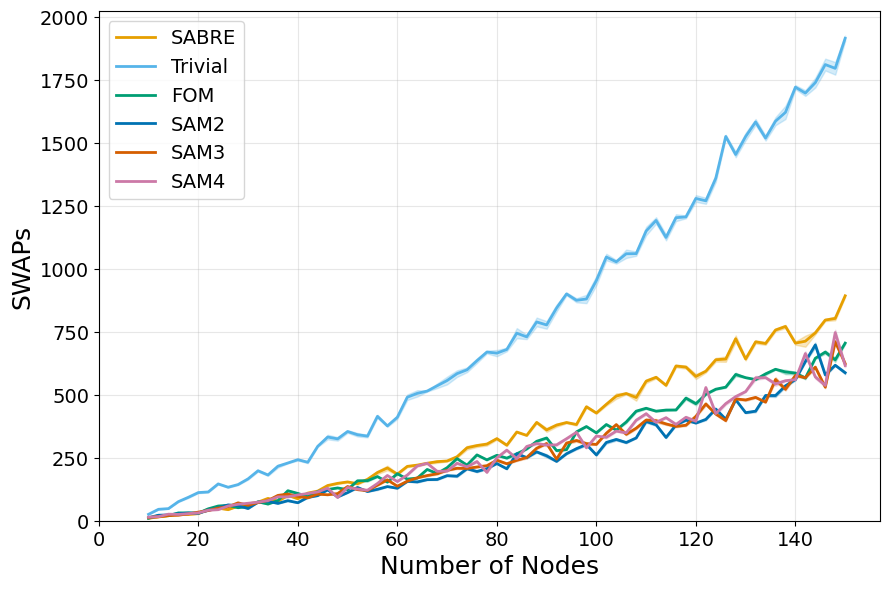

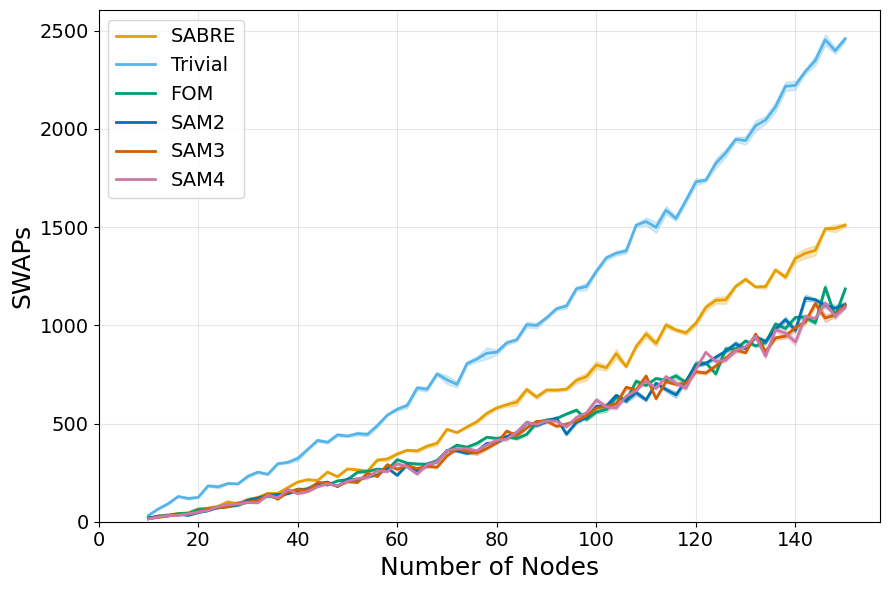

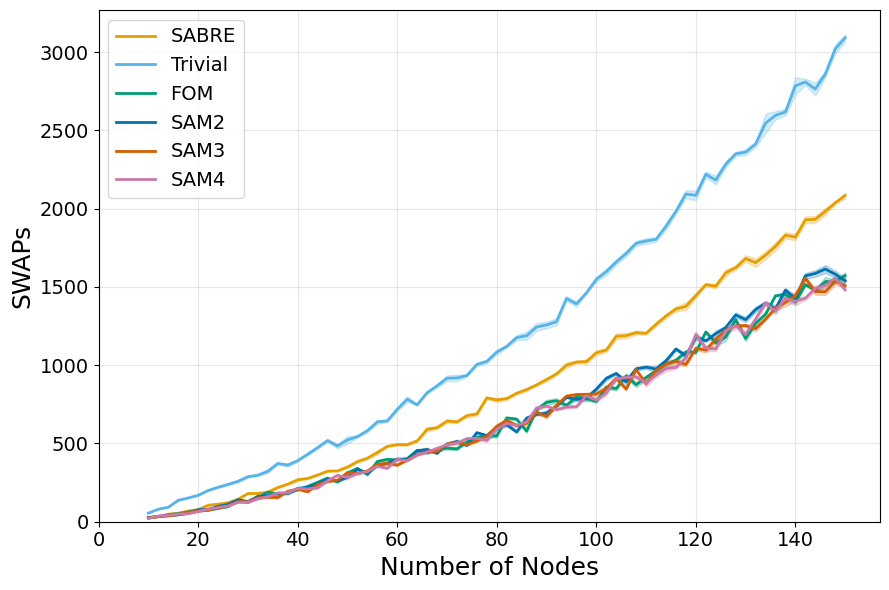

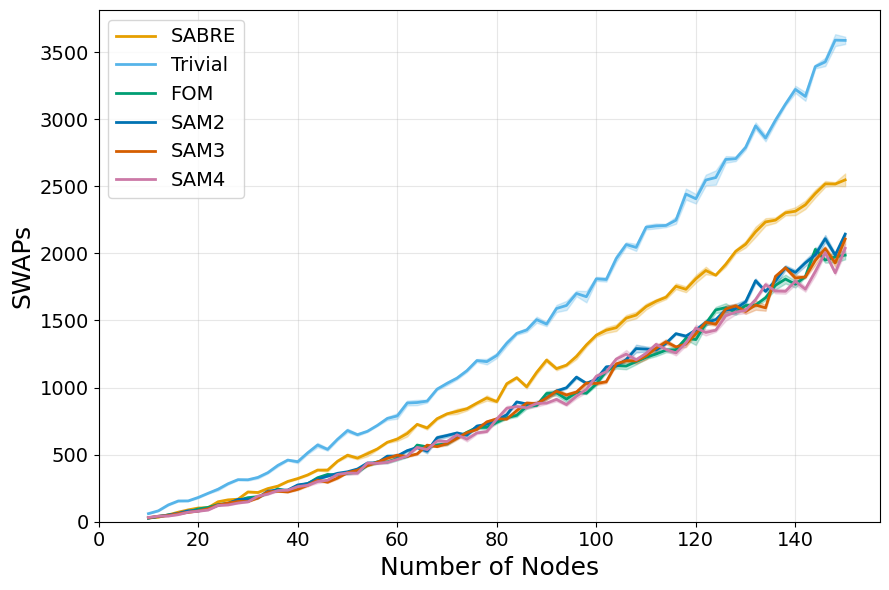

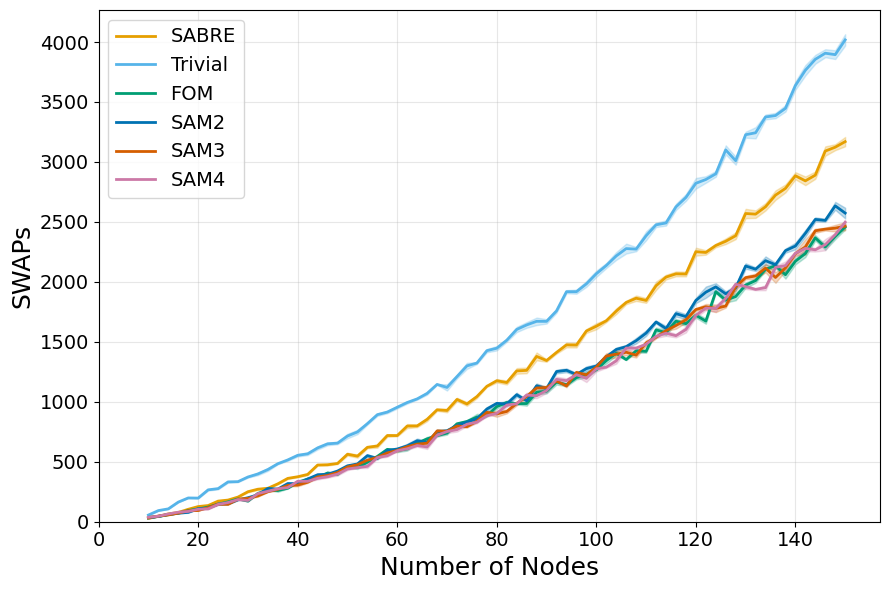

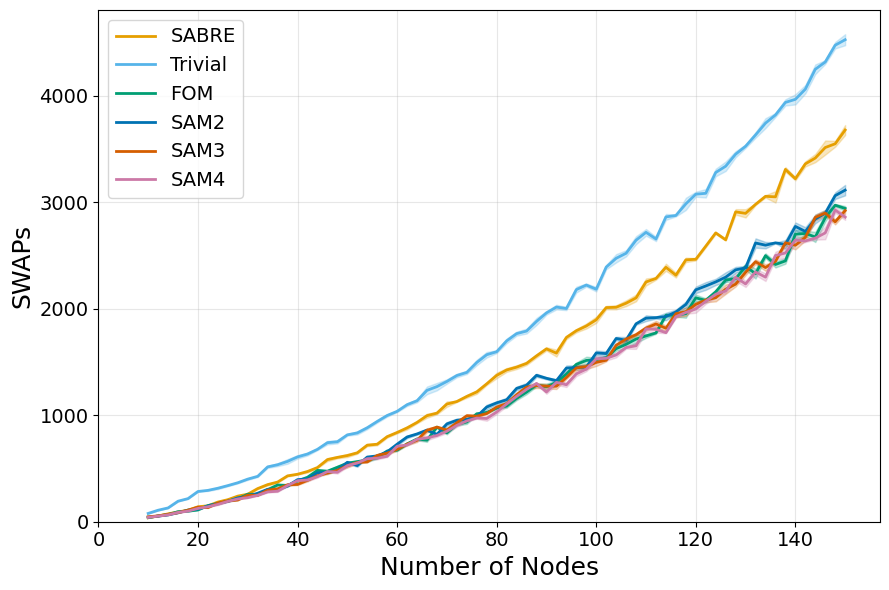

Random regular graphs: Two-qubit gate count


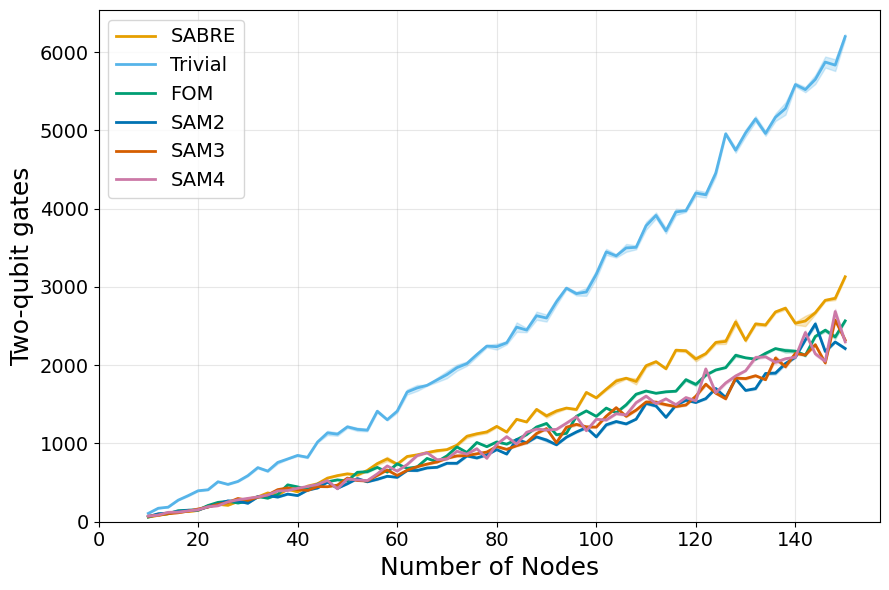

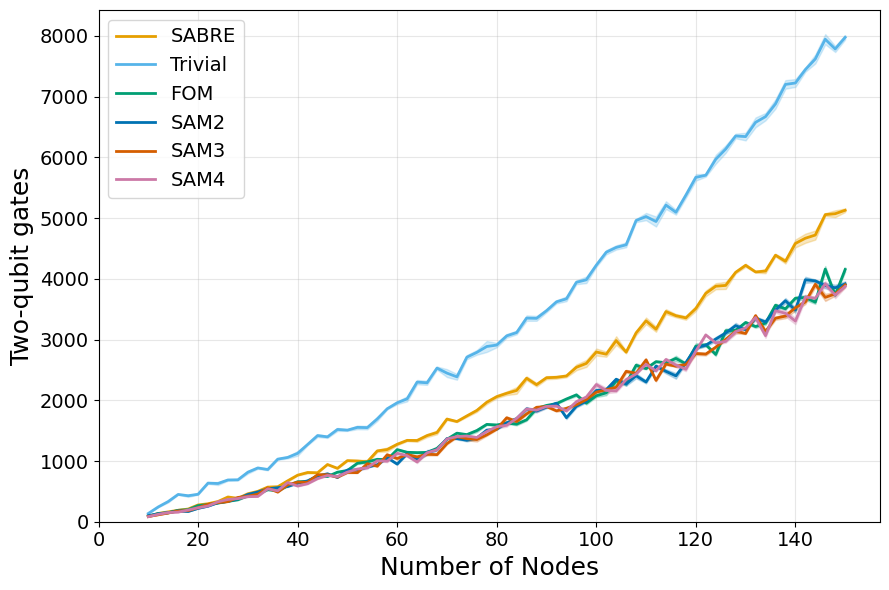

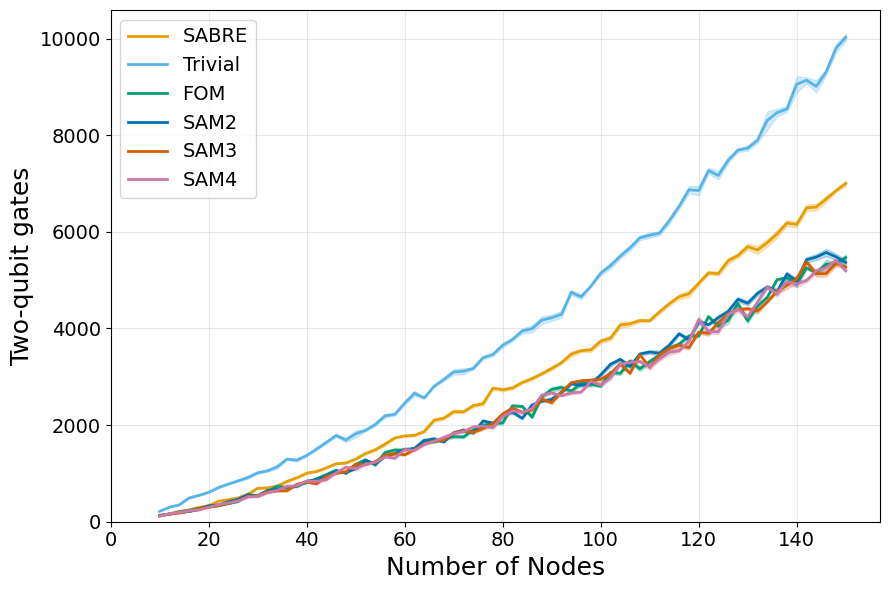

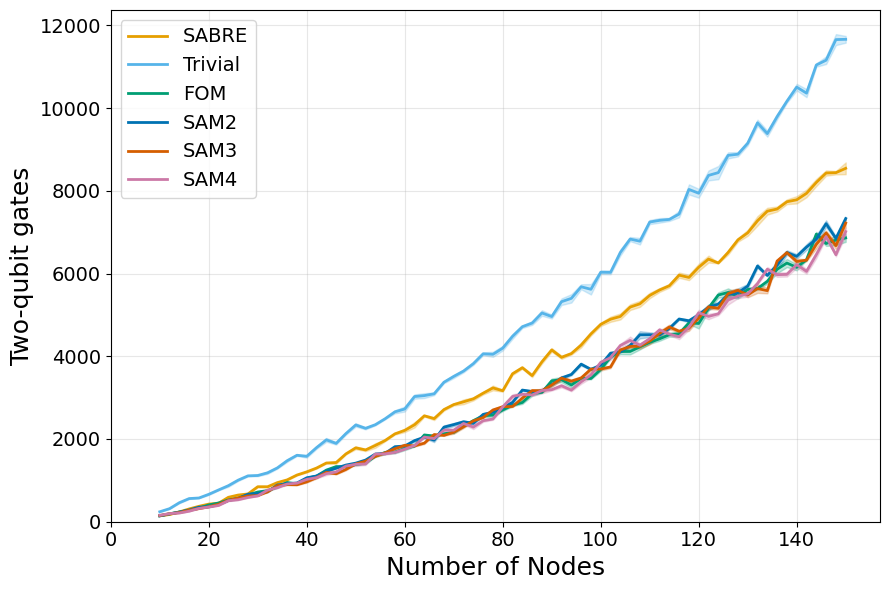

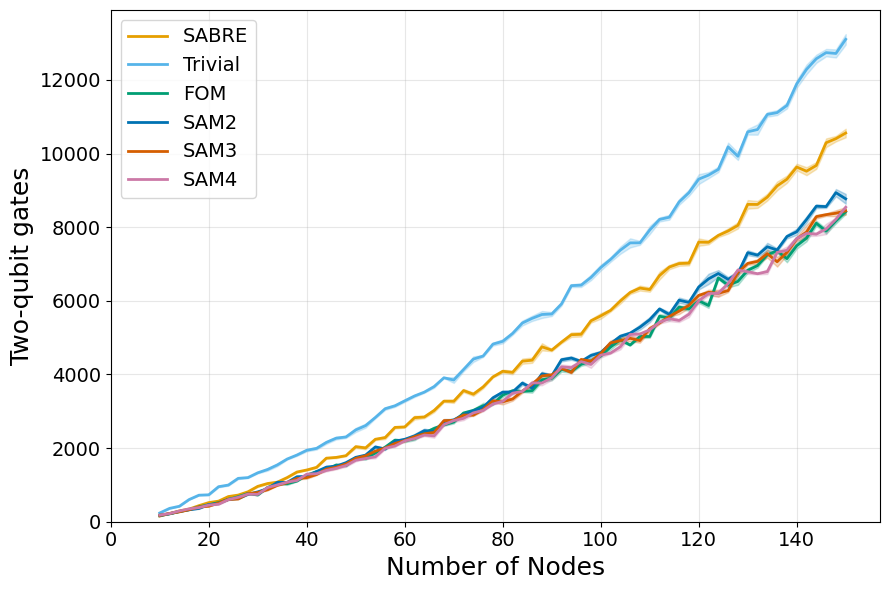

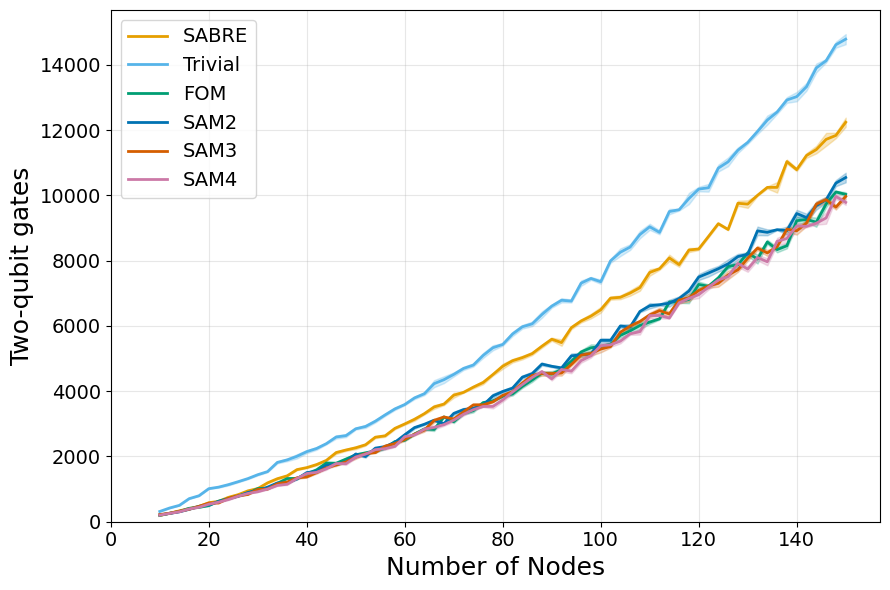

Random regular graphs: Optimized circuit depth


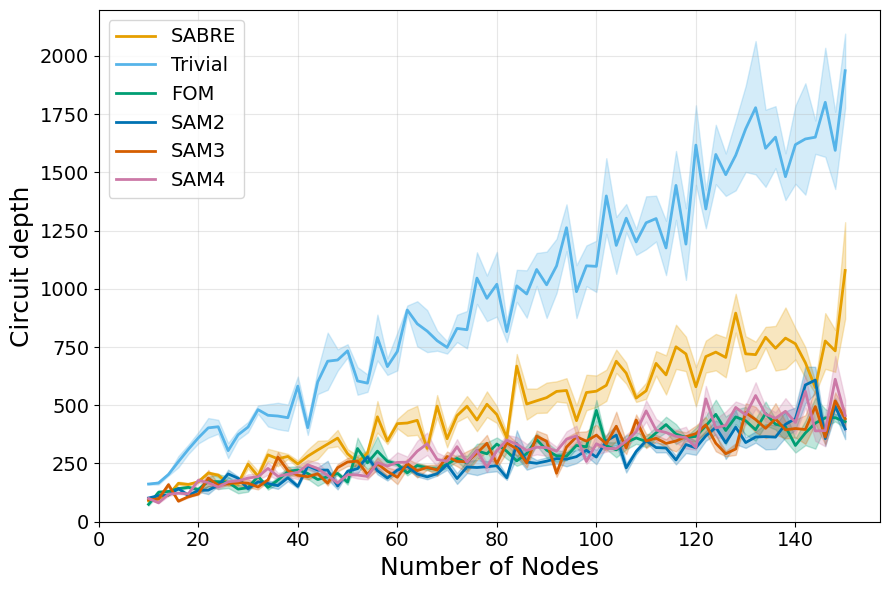

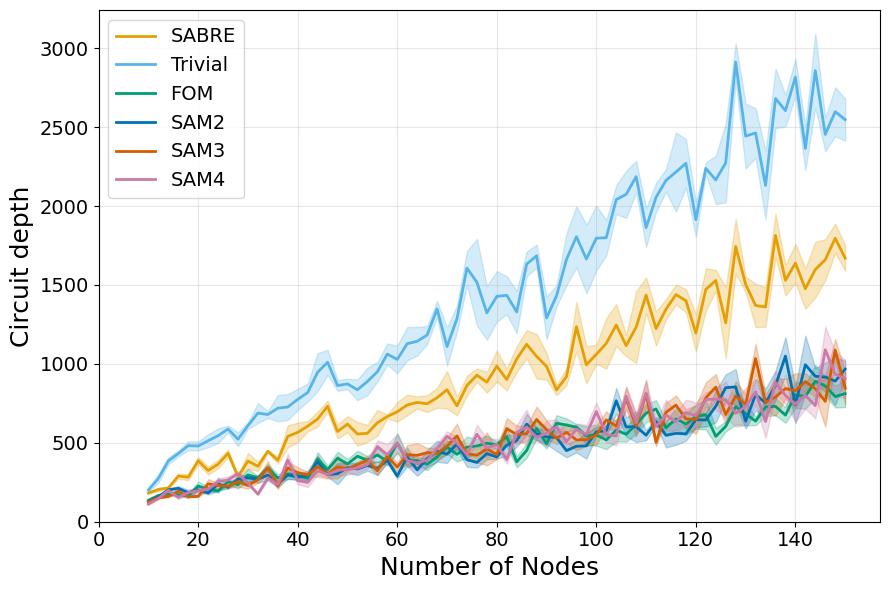

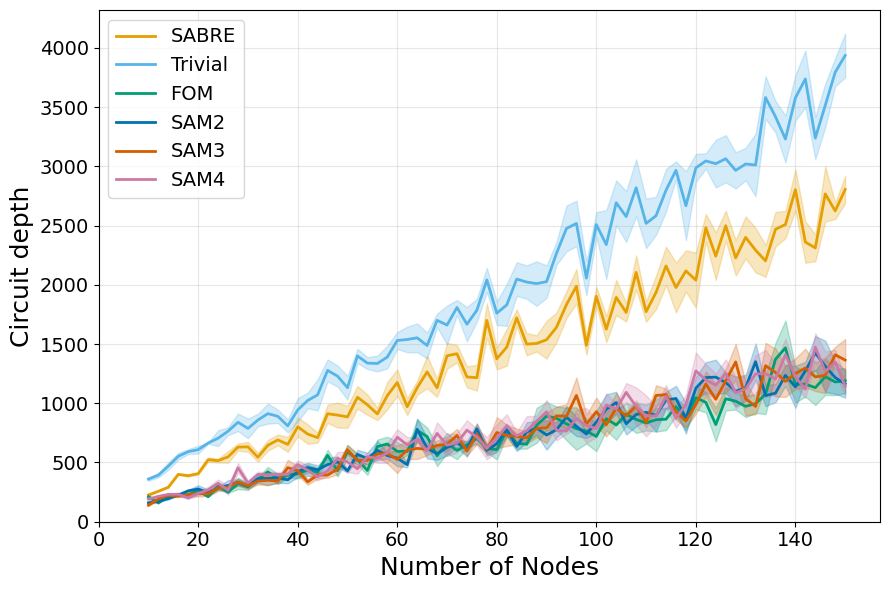

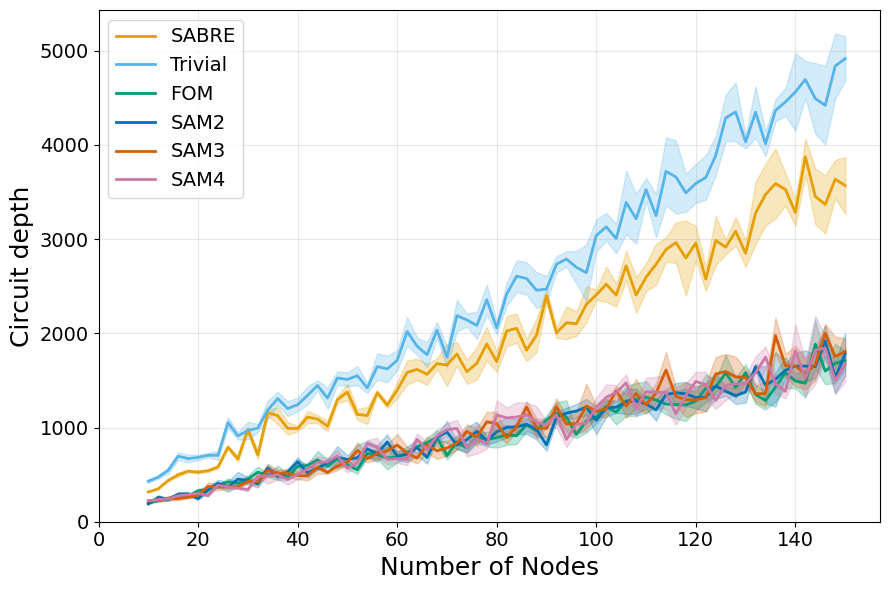

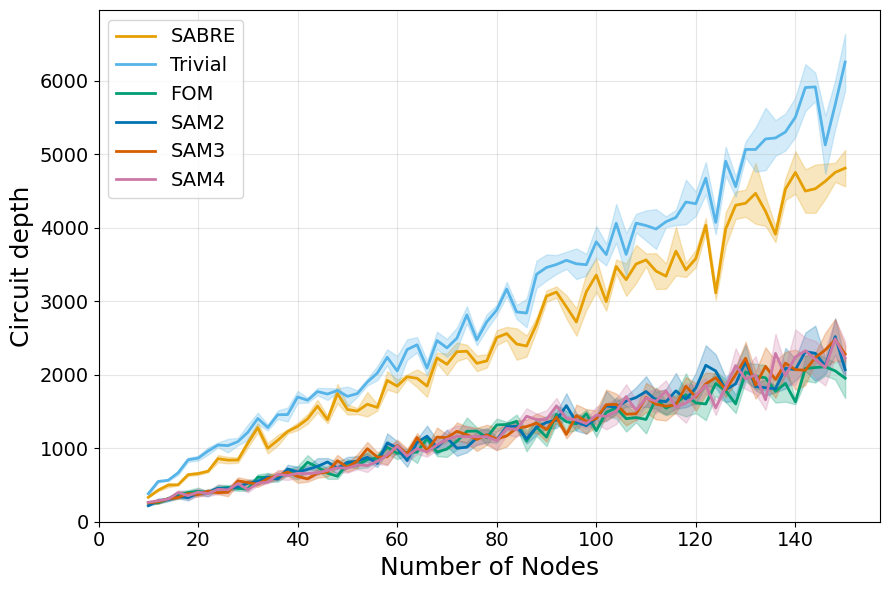

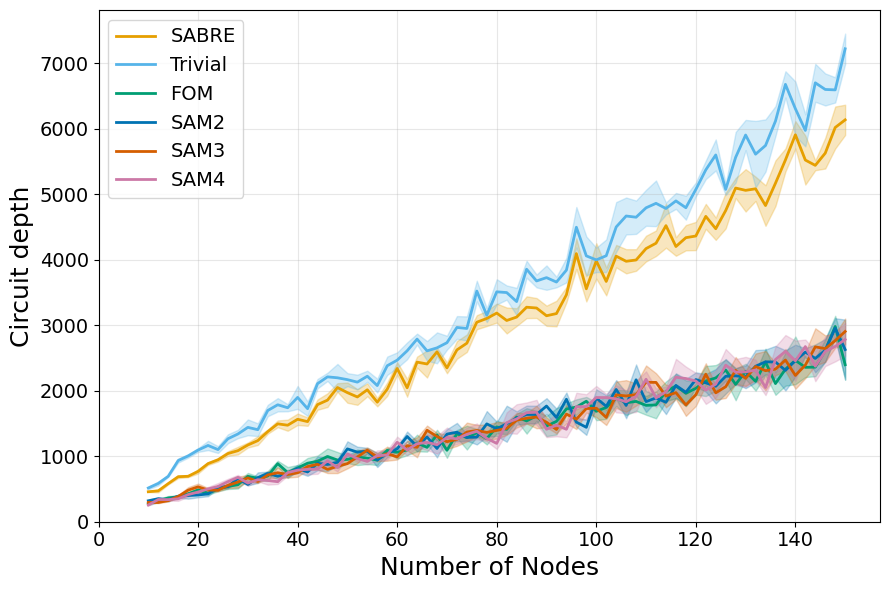

In [10]:

for metric, title, ylabel in quality_plots:
    print(f'Random regular graphs: {title}')
    plot_metric_results(
        results_reg, nodes_reg, k_list, params_reg, metric=metric,
        title_prefix=f'Random regular graphs: {title}', ylabel=ylabel,
    )

# RR Time

In [17]:
times_reg = {}
for param in params_reg:
    times_reg[param] = return_times_all_methods(
        backend,
        graph_type='reg',
        param=param,
        average_over=average_over,
        node_list=nodes_reg,
        k_list=k_list,
        reps=reps,
        opt_level=opt_level,
        noise_aware=True,
    )

Random regular graphs: Mapping time


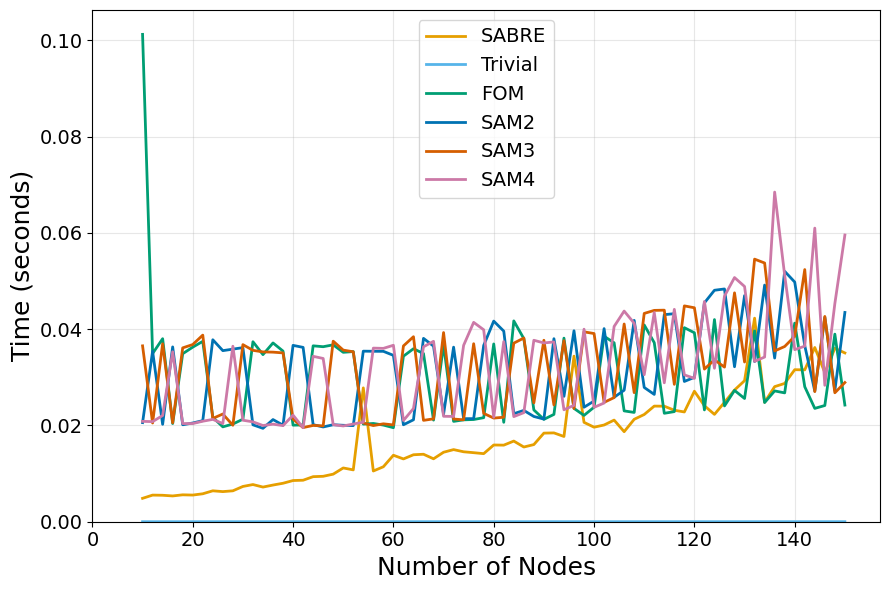

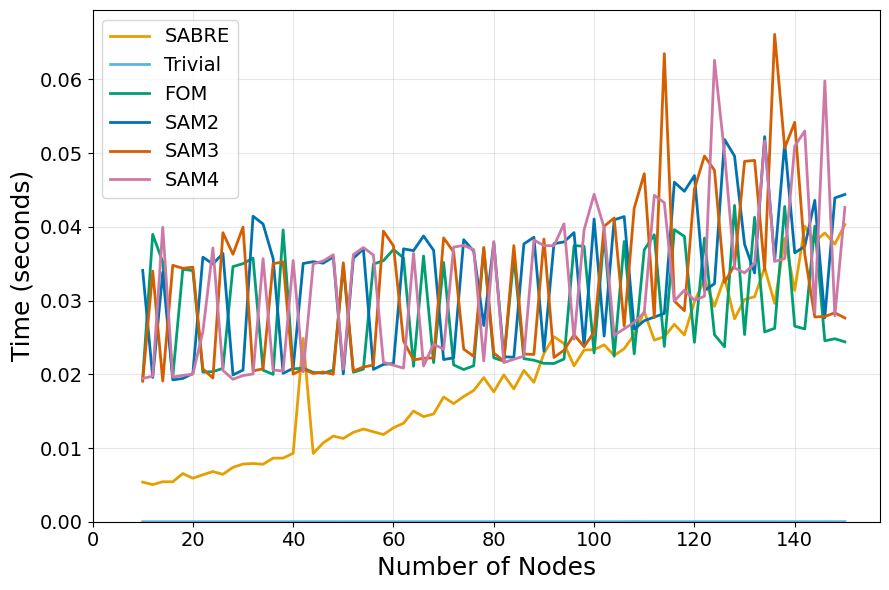

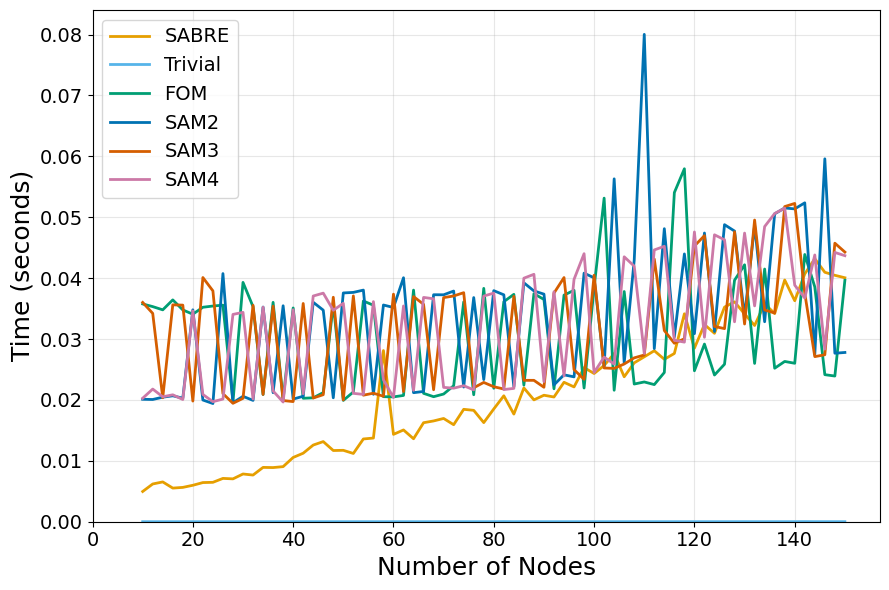

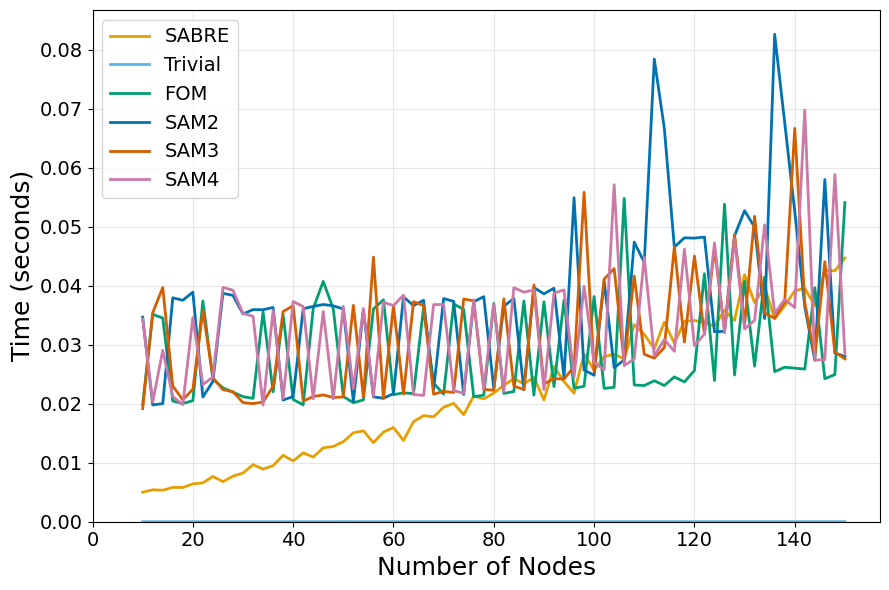

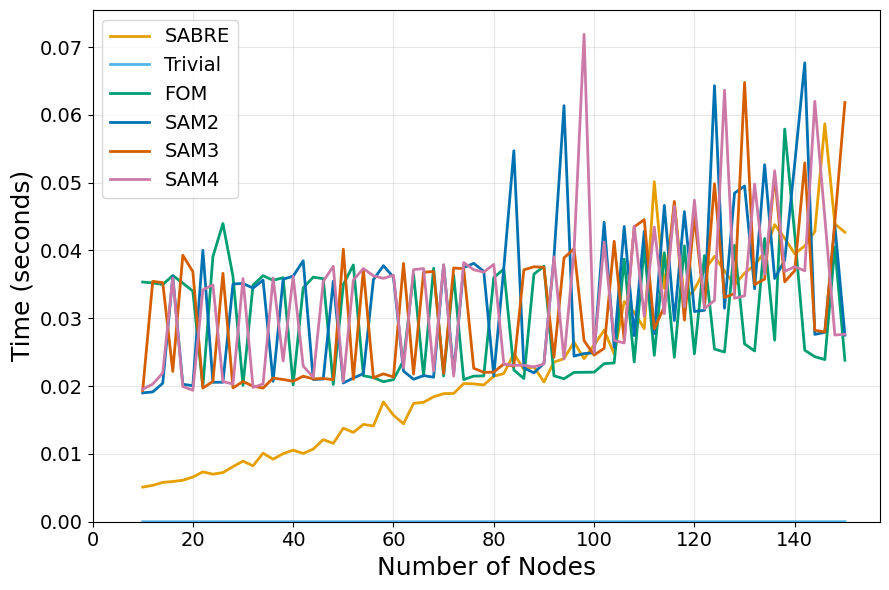

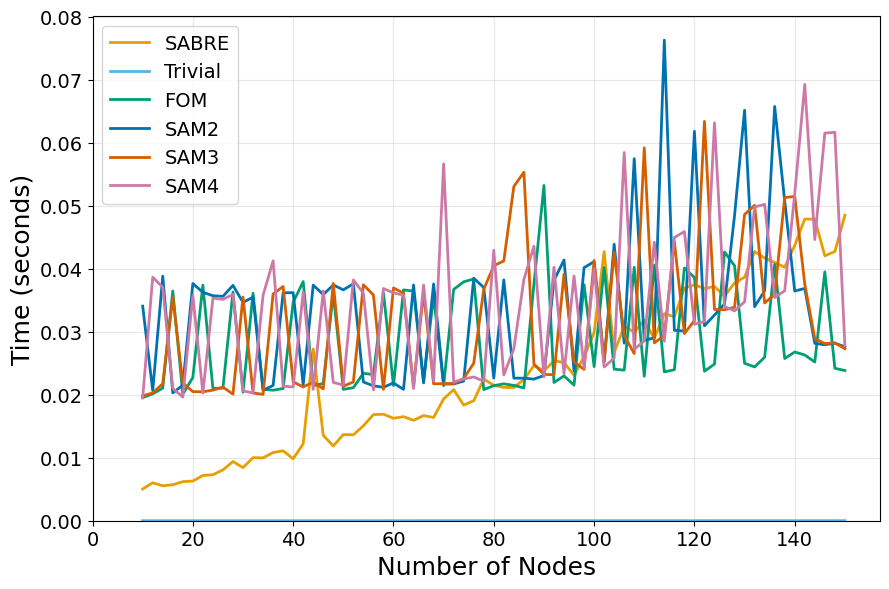

Random regular graphs: Routing time


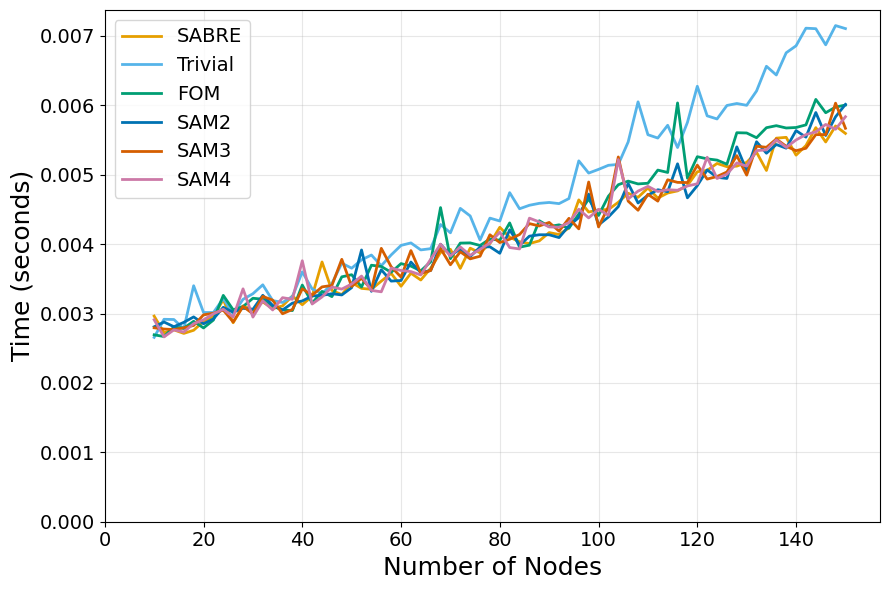

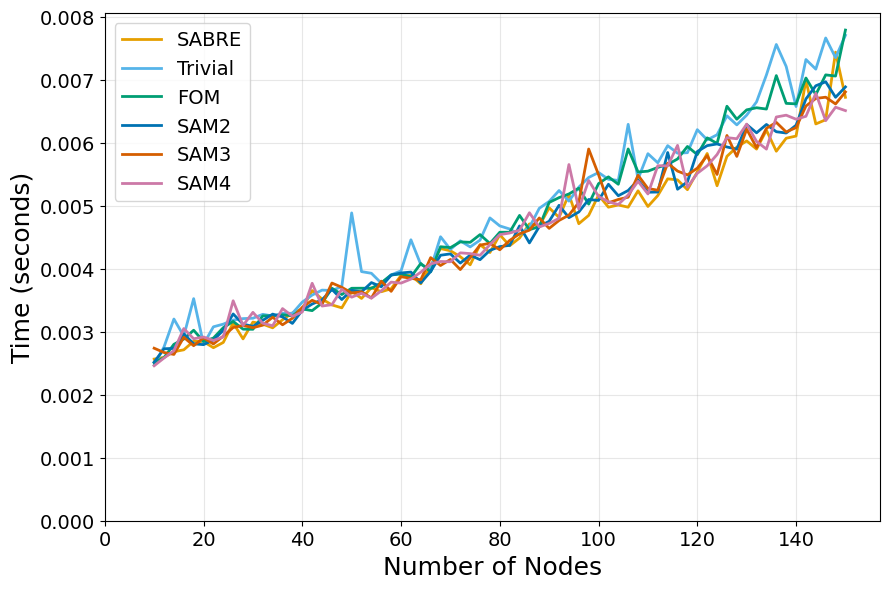

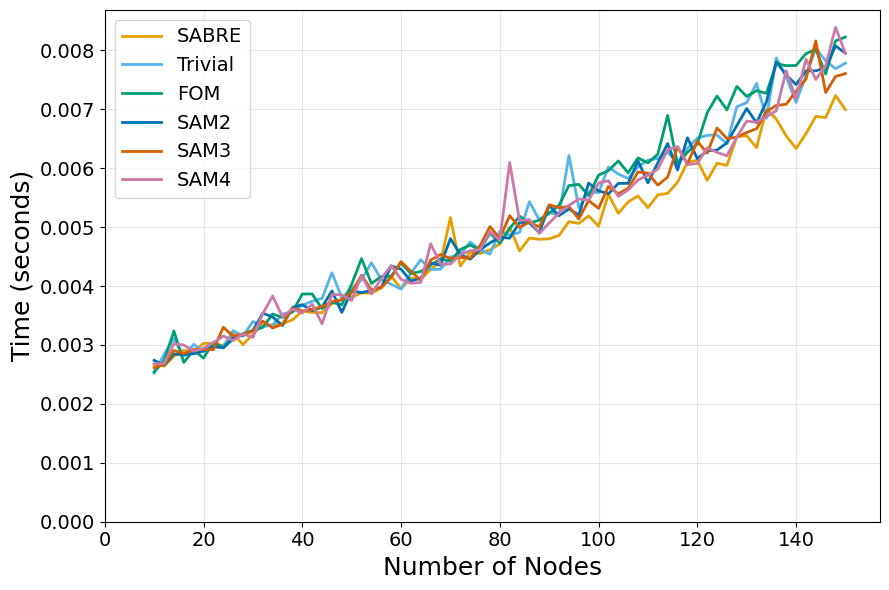

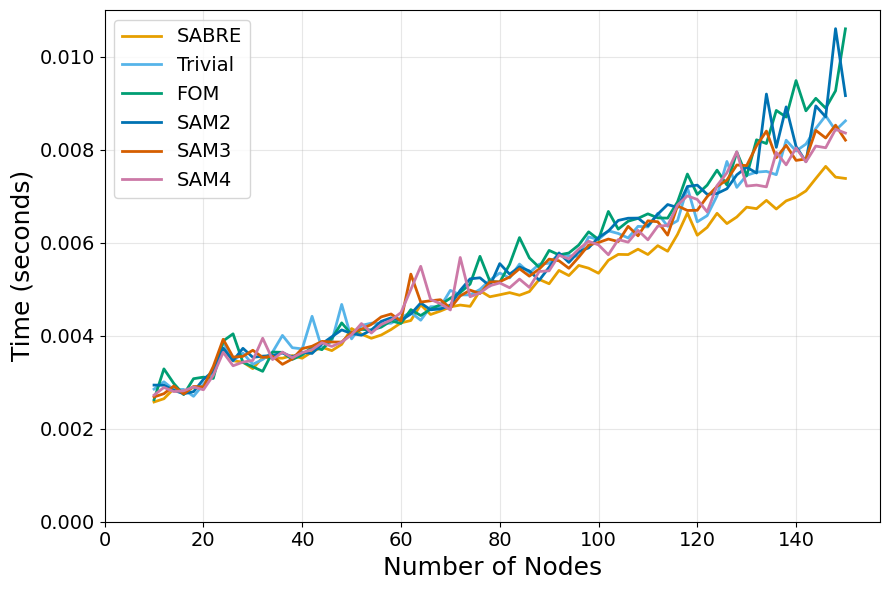

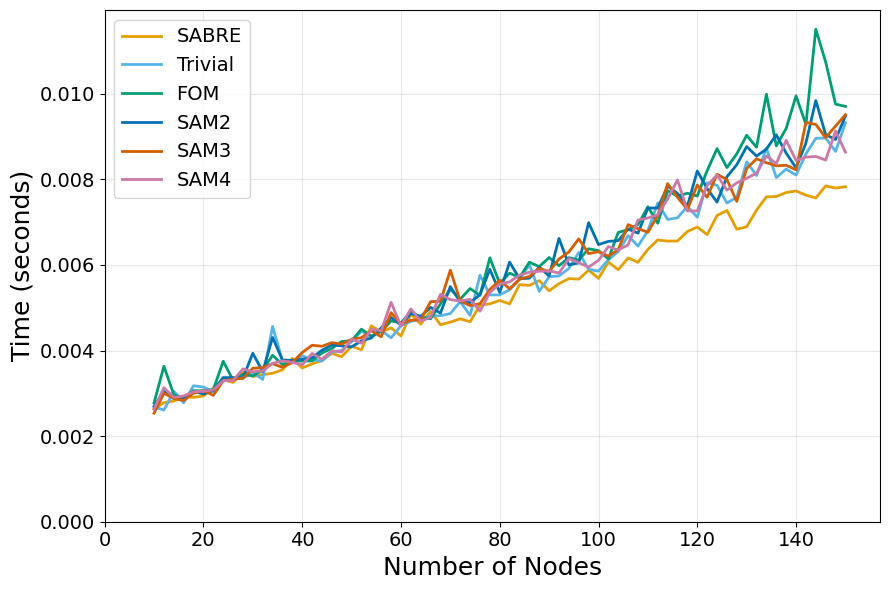

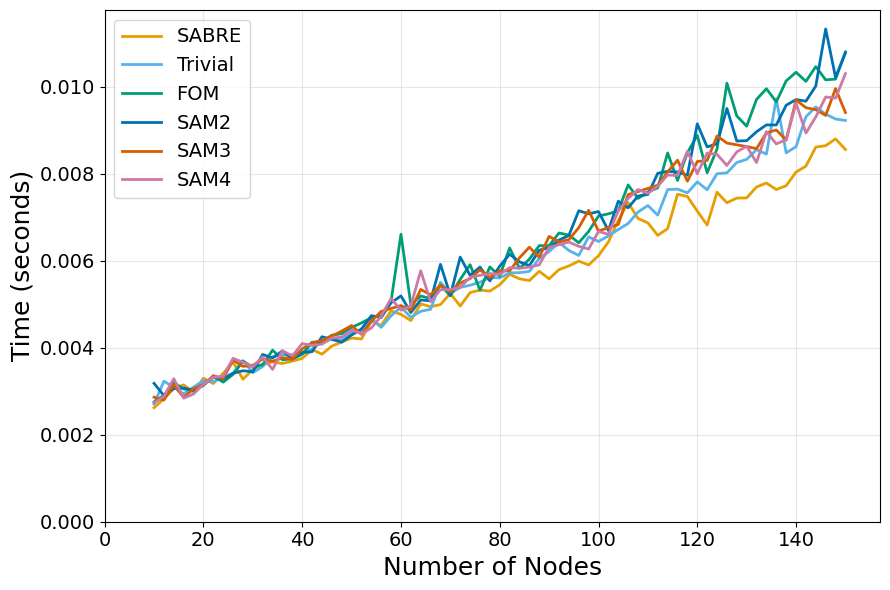

Random regular graphs: Final optimization time


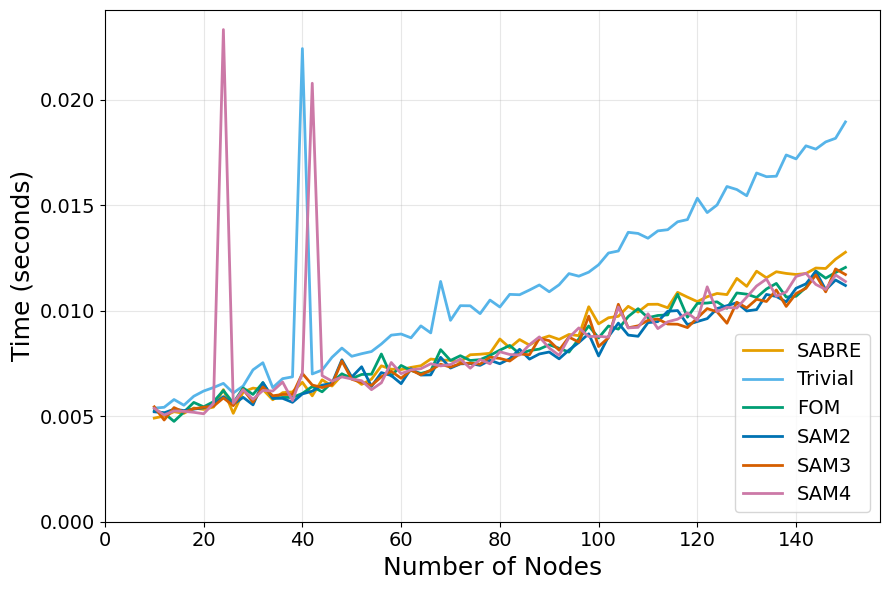

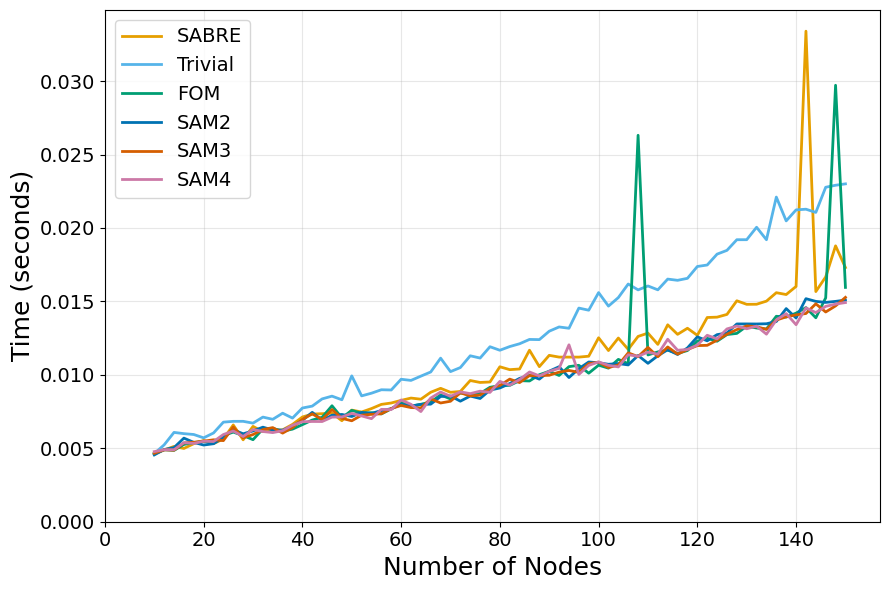

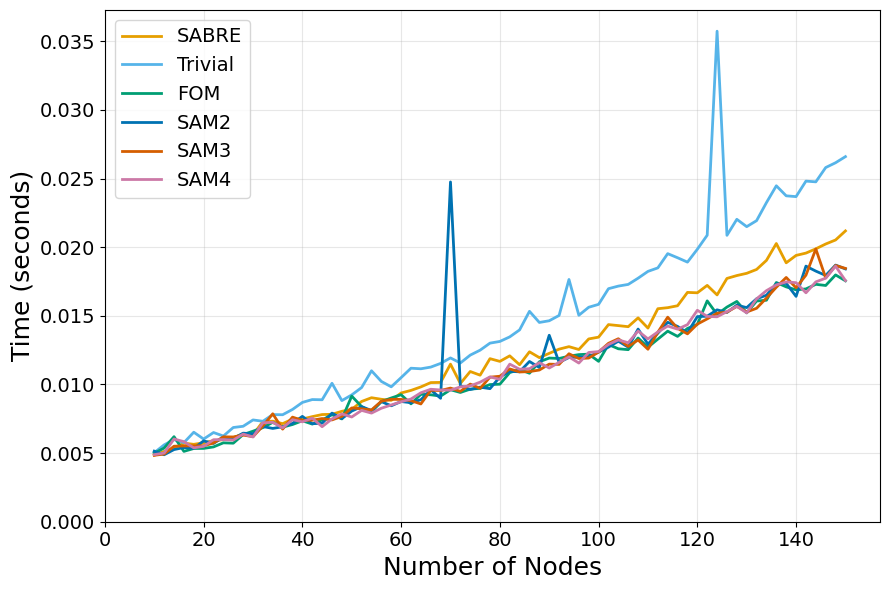

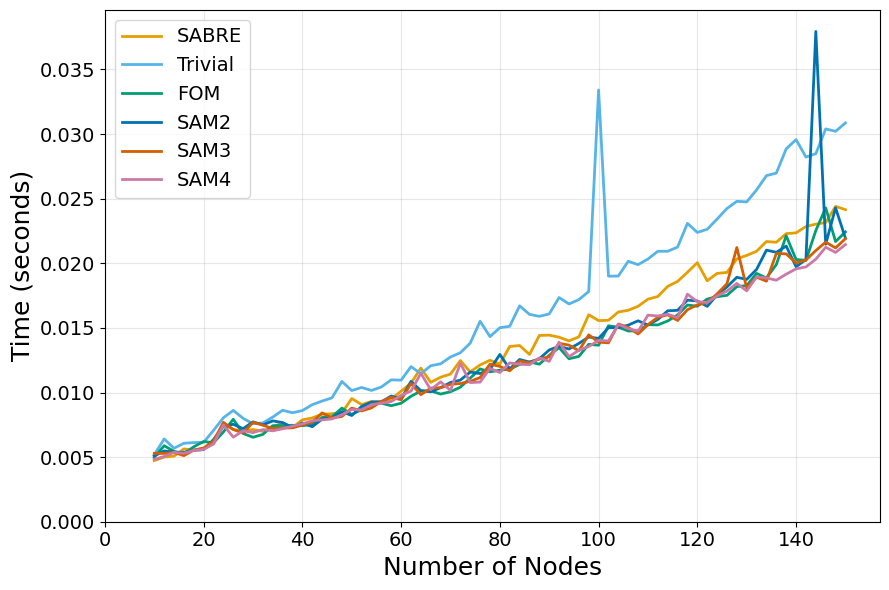

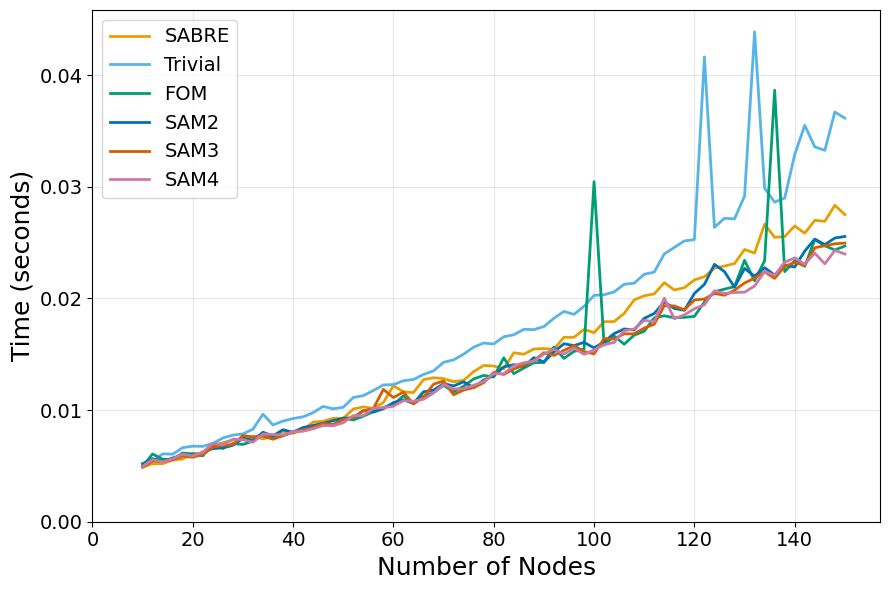

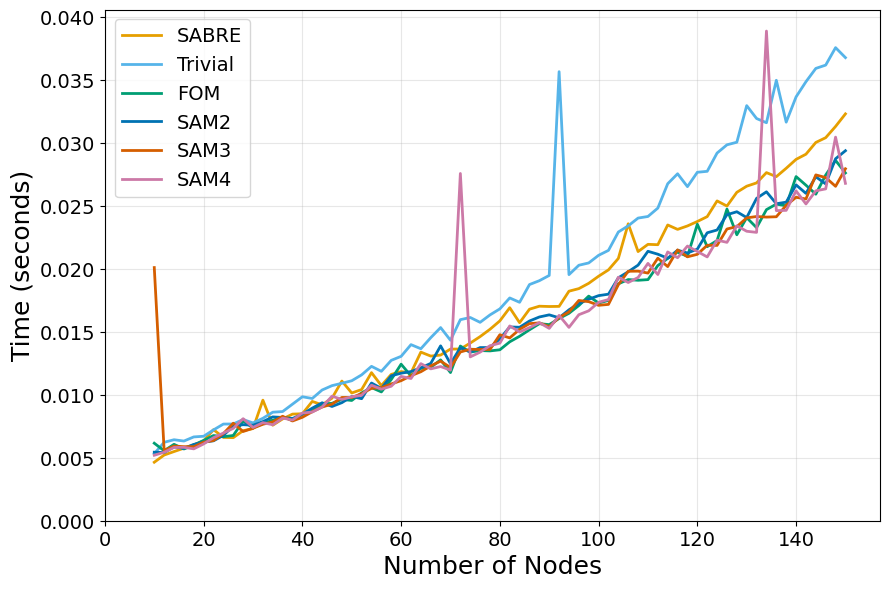

Random regular graphs: Total compilation time


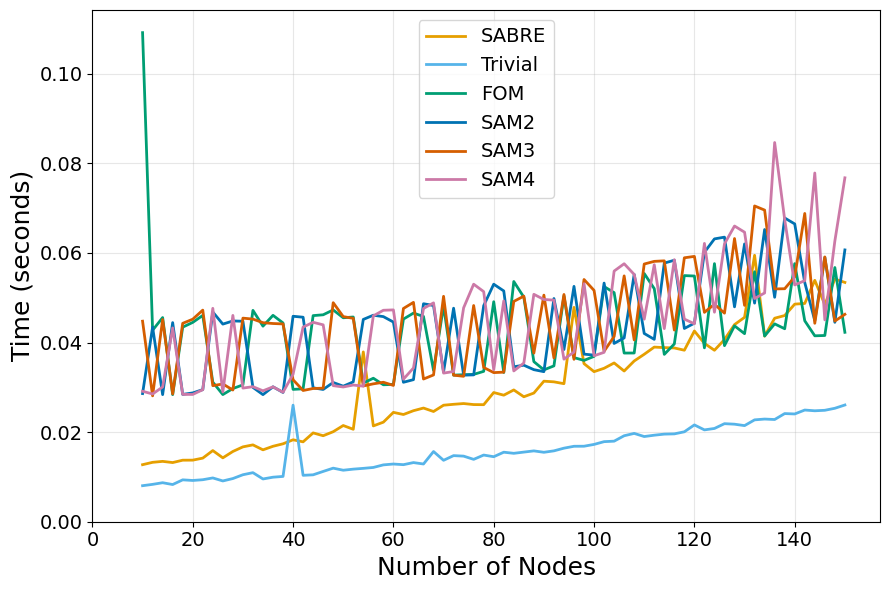

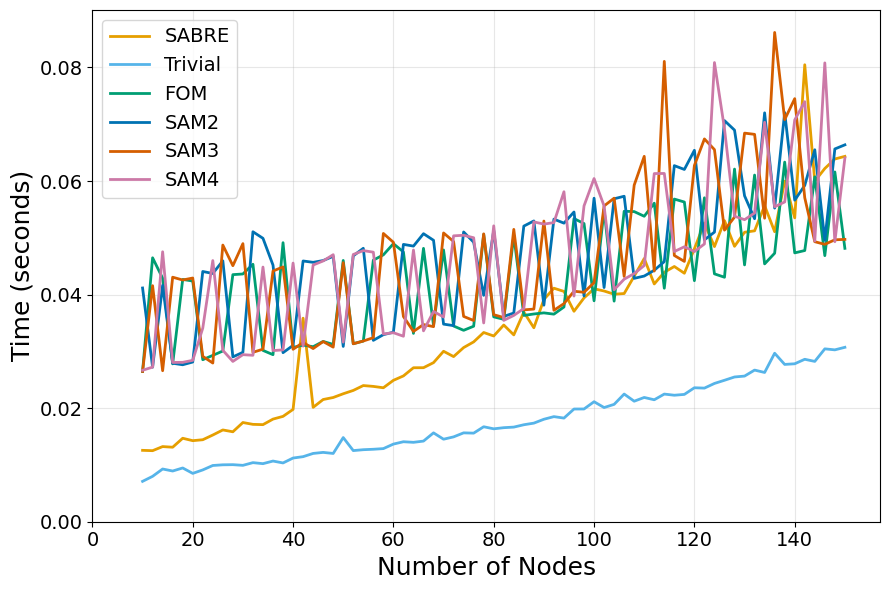

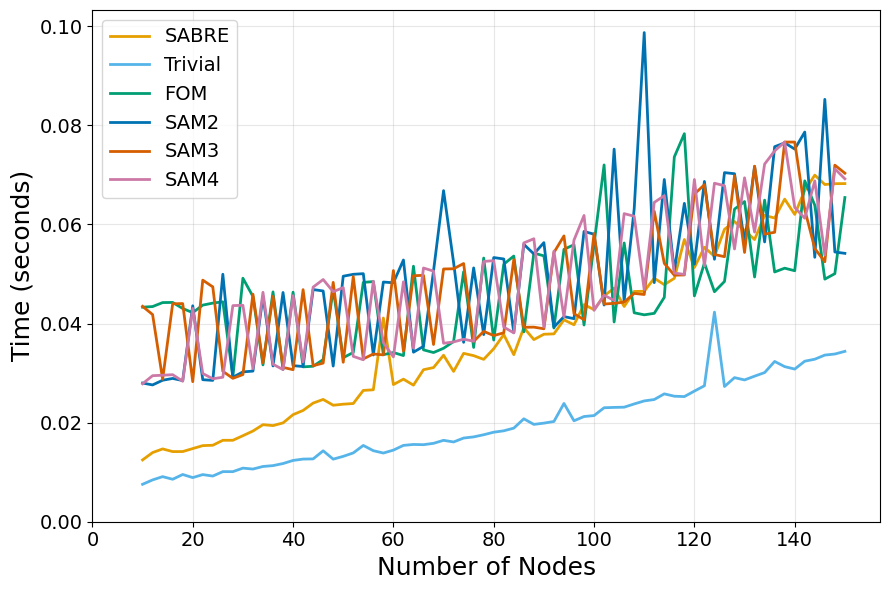

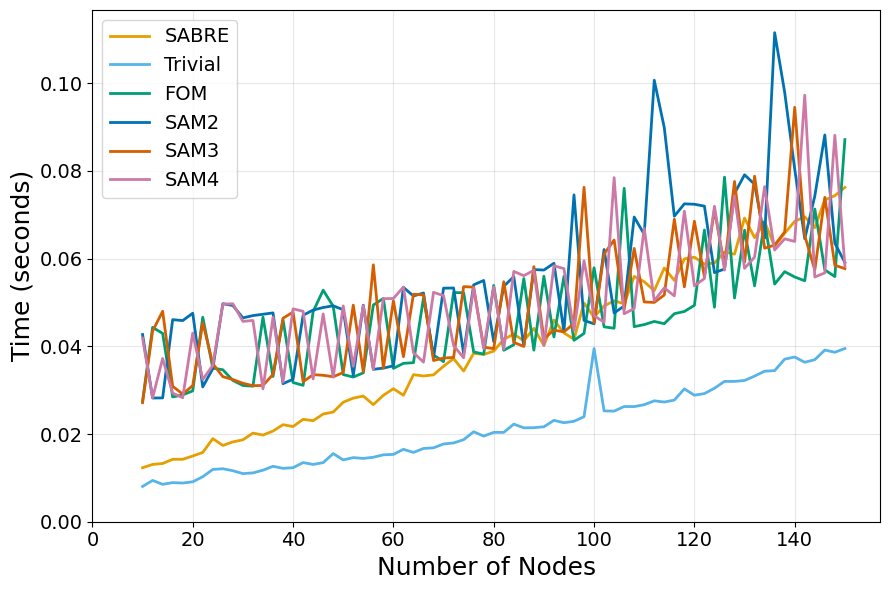

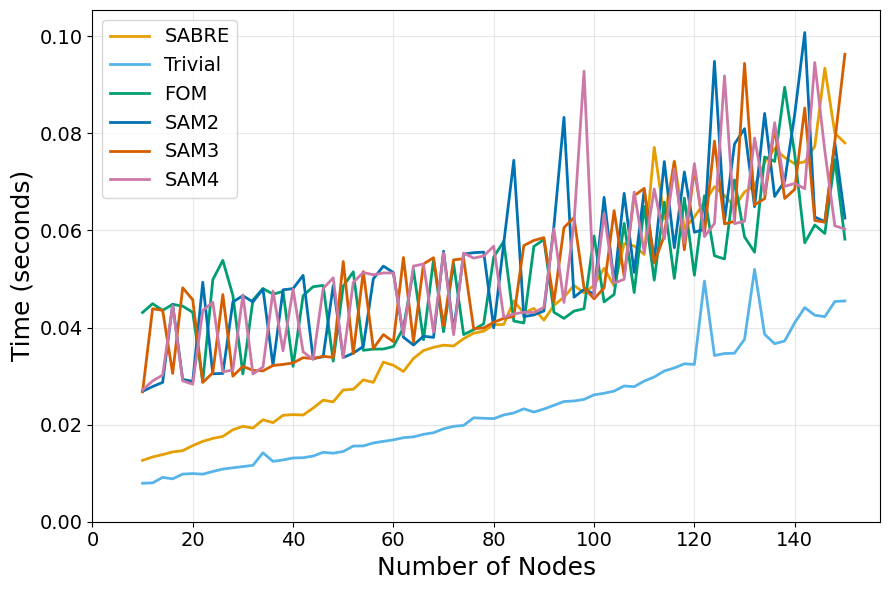

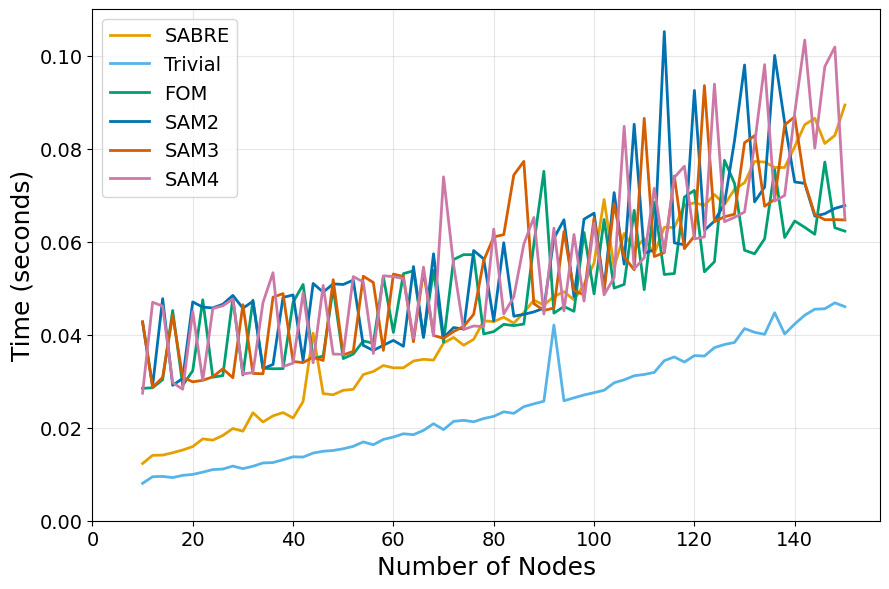

In [20]:

for metric, title, ylabel in time_plots:
    print(f'Random regular graphs: {title}')
    plot_metric_results(
        times_reg, nodes_reg, k_list, params_reg, metric=metric,
        title_prefix=f'Random regular graphs: {title}', ylabel=ylabel, fill_between=False, plot='mean'
    )


# BA Circuit Quality

Barabasi-Albert graphs: SWAP count


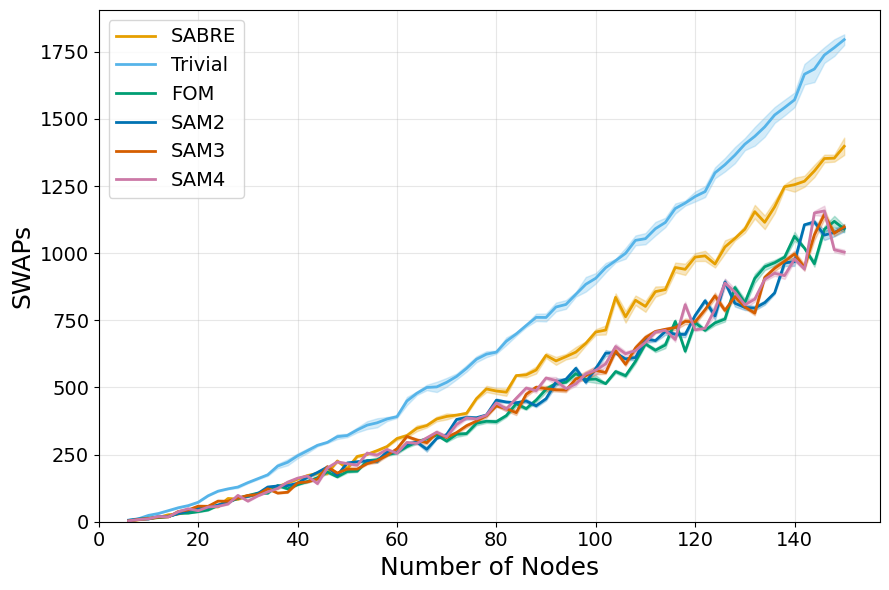

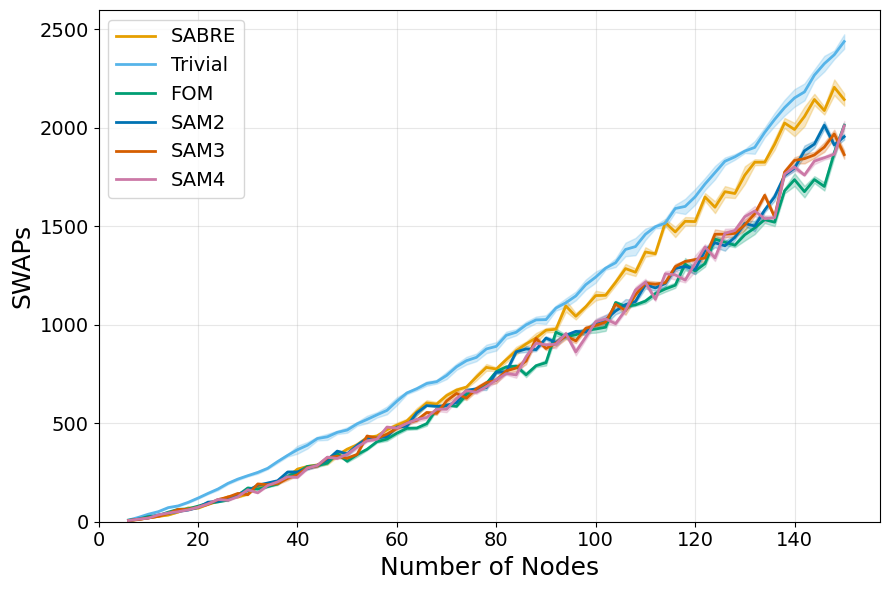

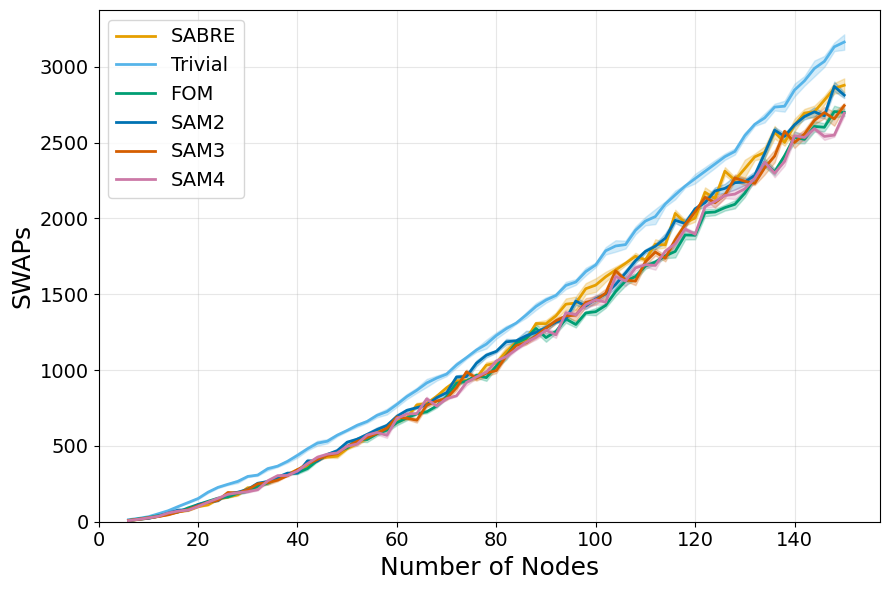

Barabasi-Albert graphs: Two-qubit gate count


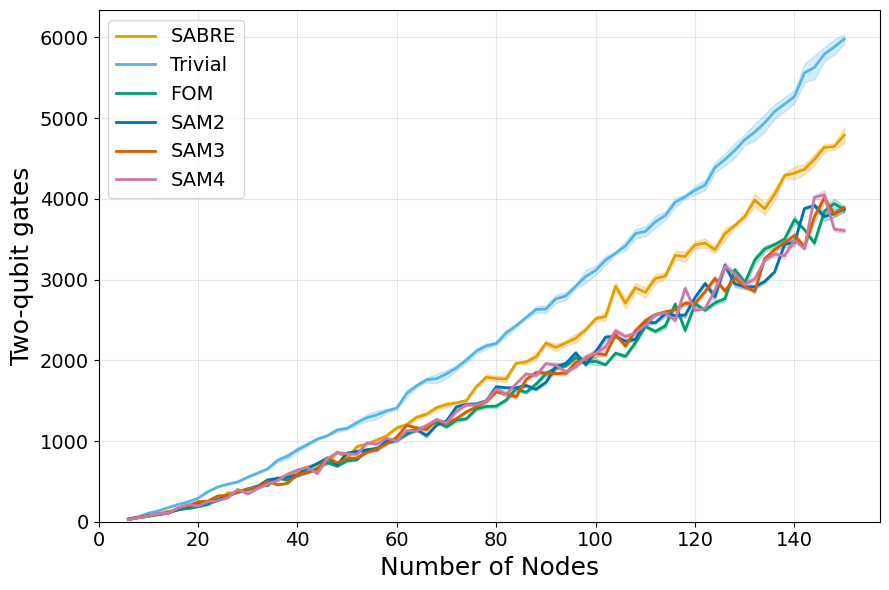

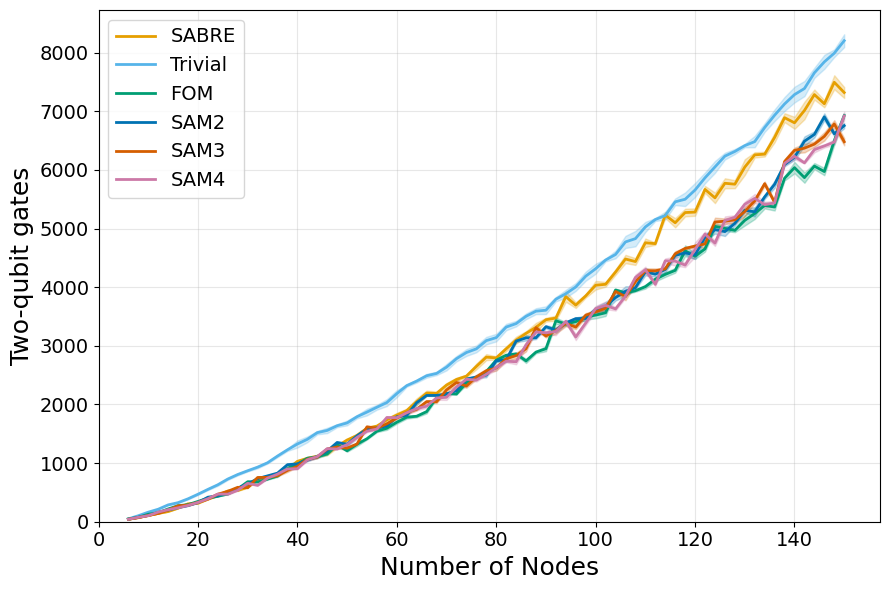

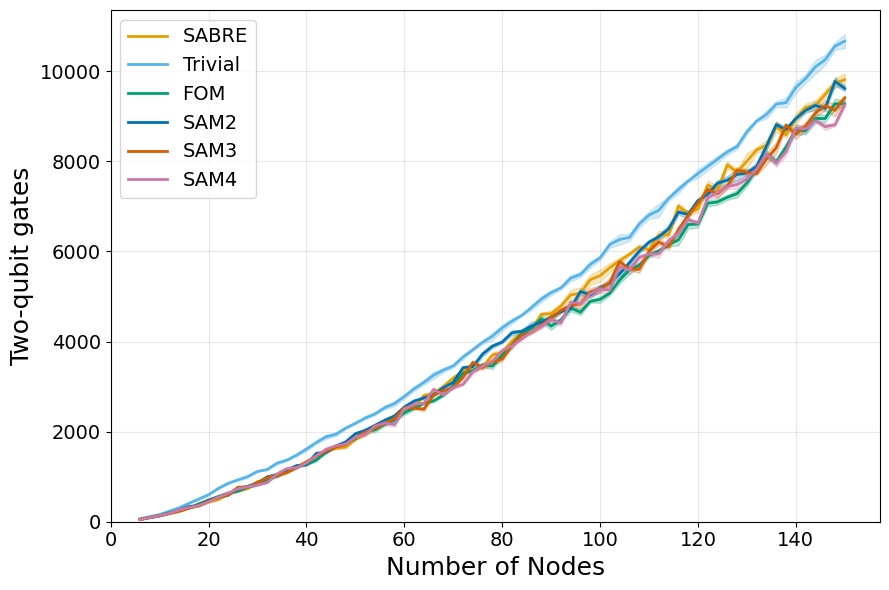

Barabasi-Albert graphs: Optimized circuit depth


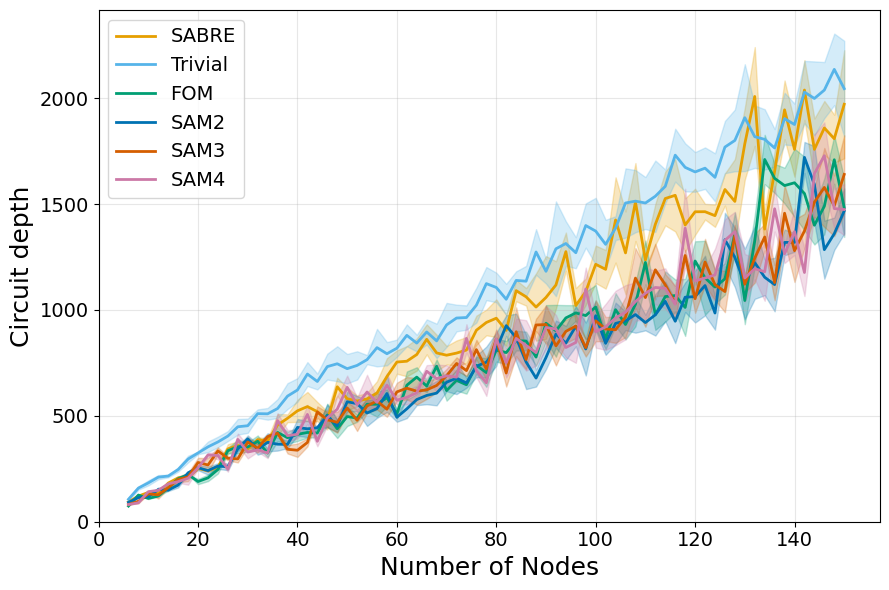

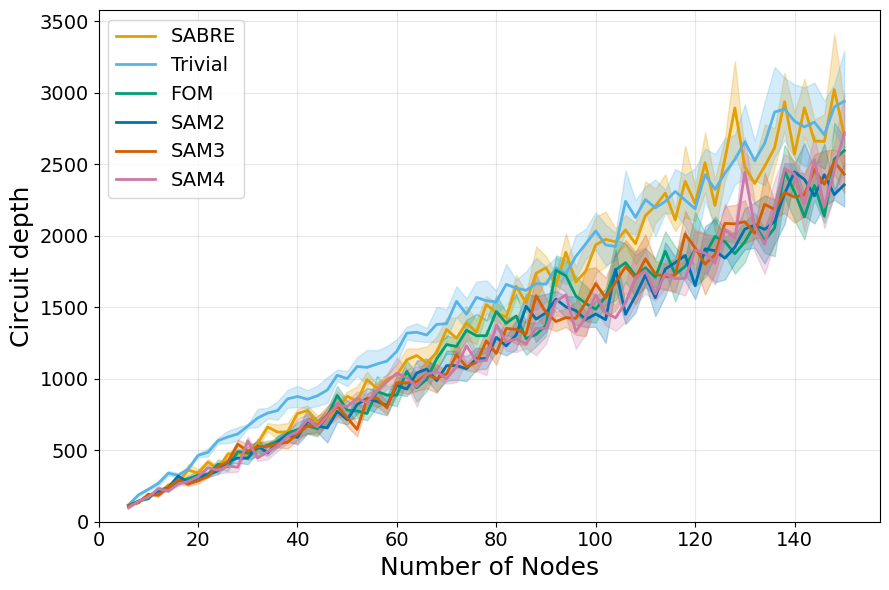

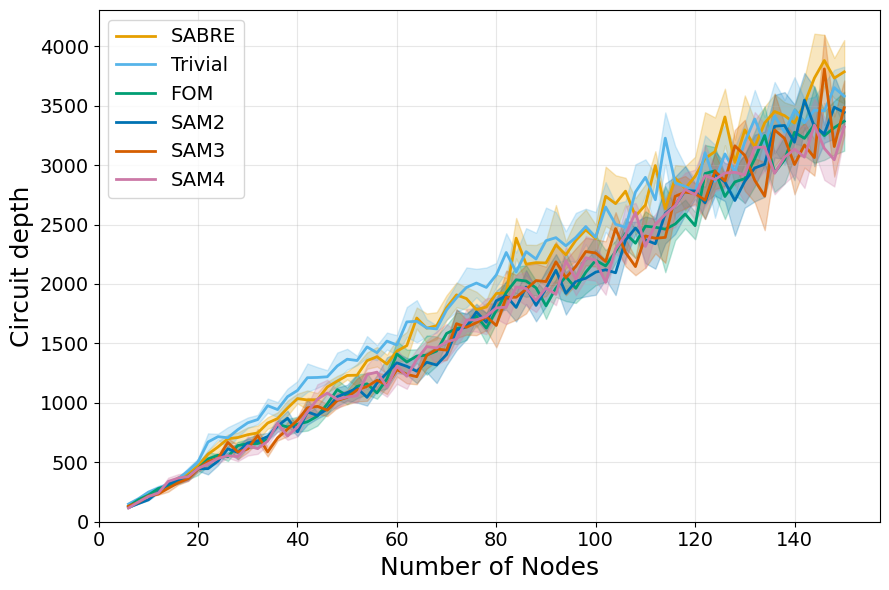

In [13]:
for metric, title, ylabel in quality_plots:
    print(f'Barabasi-Albert graphs: {title}')
    plot_metric_results(
        results_ba, nodes_ba, k_list, params_ba, metric=metric,
        title_prefix=f'Barabasi-Albert graphs: {title}', ylabel=ylabel,
    )

## Combined SWAP and two-qubit-gate plots

Each plot overlays SWAP count (solid) and optimized two-qubit-gate count (dashed). Color denotes the routing method. The plot reads the cached `return_ops_all_methods` results above, so changing this cell does not rerun compilation.


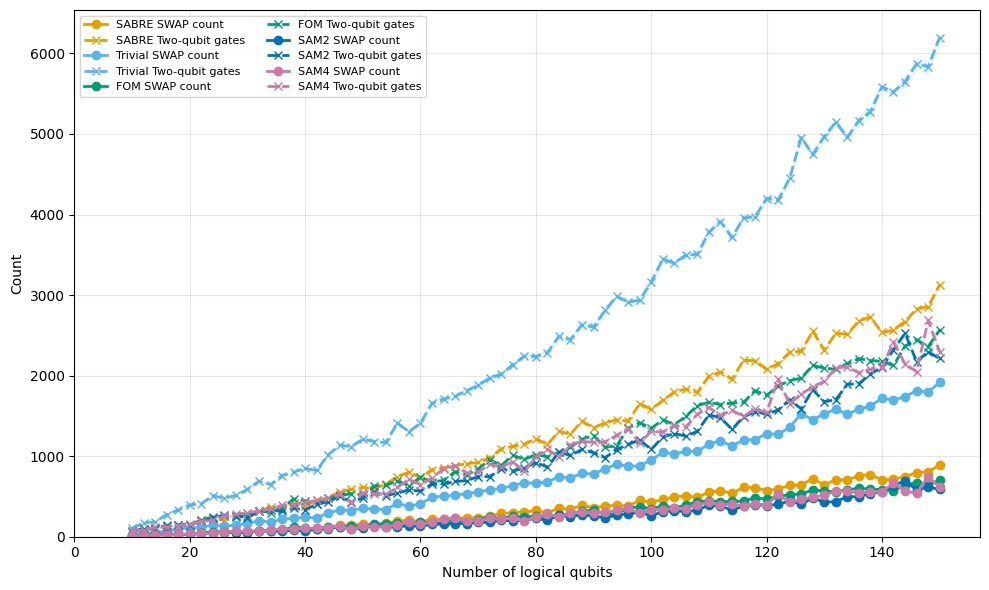

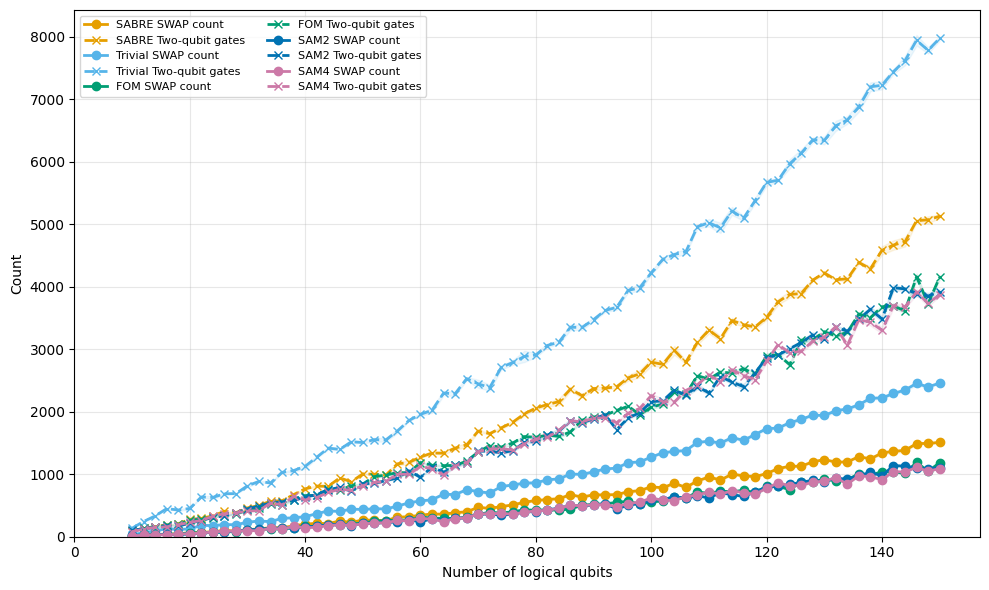

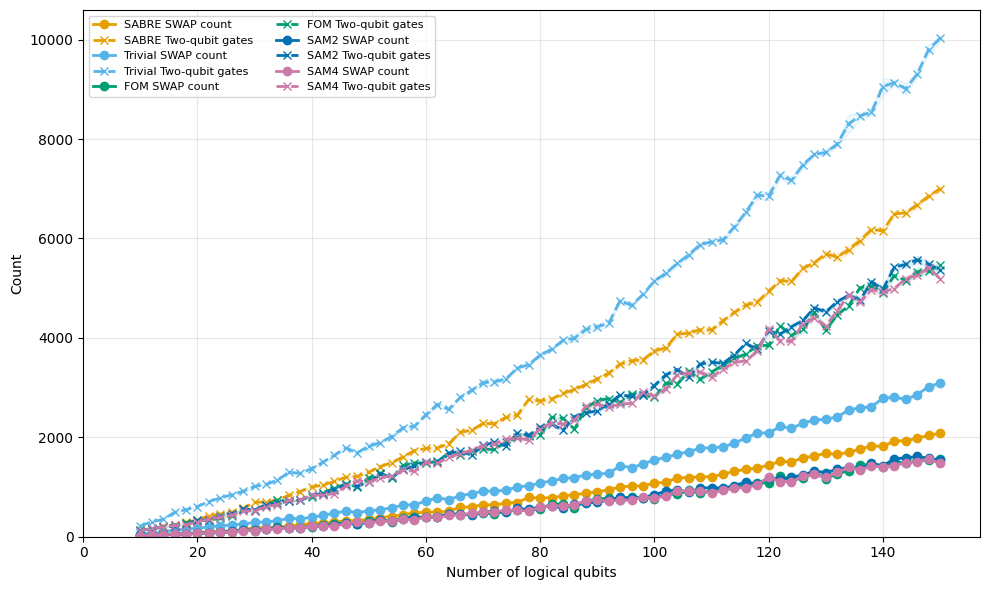

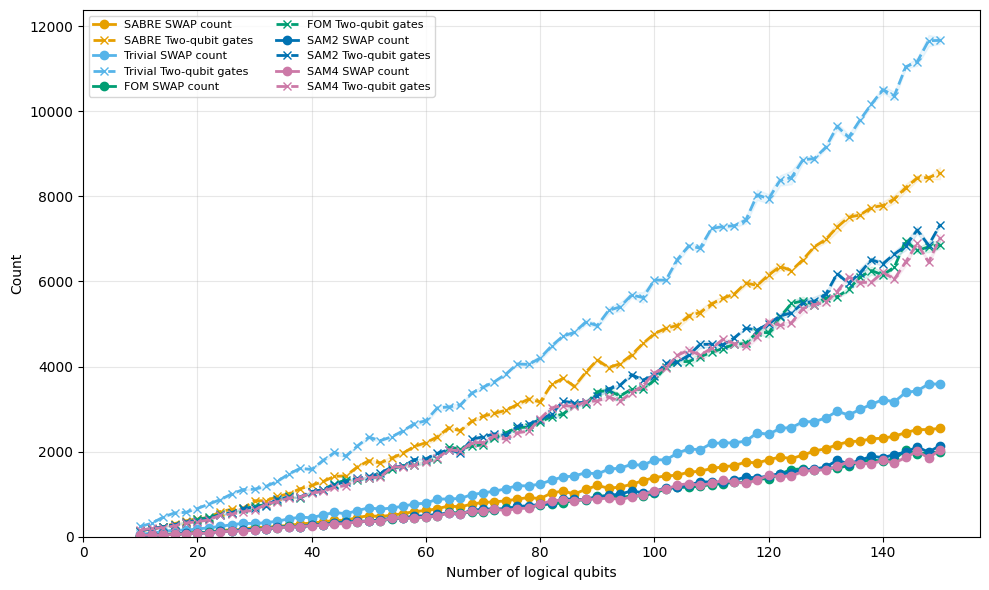

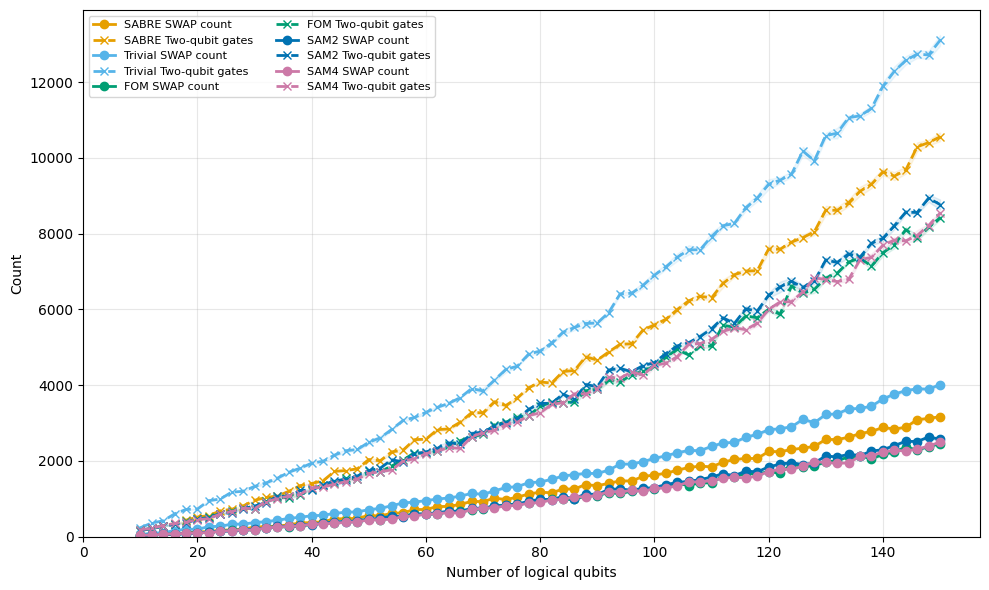

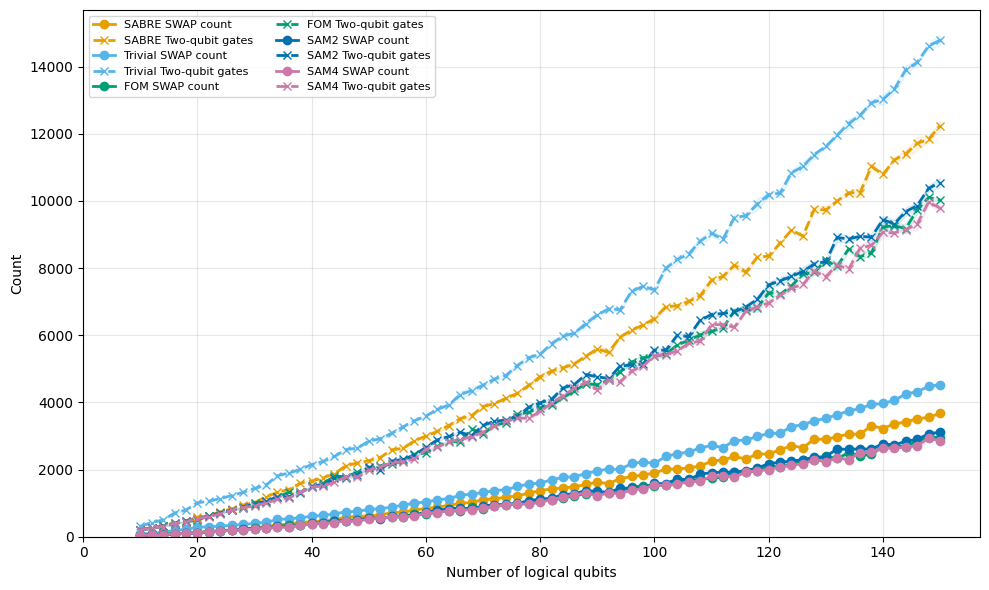

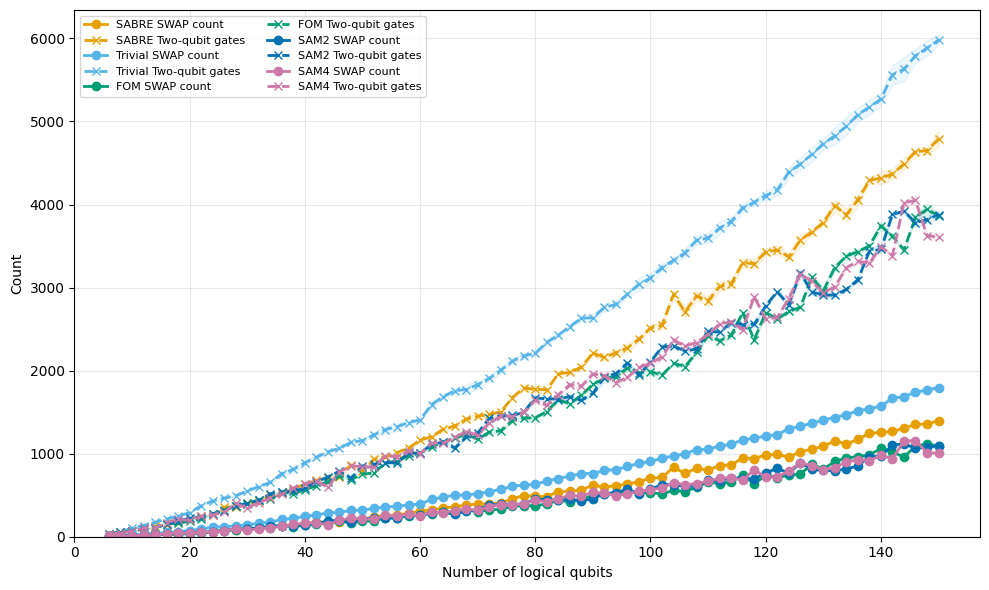

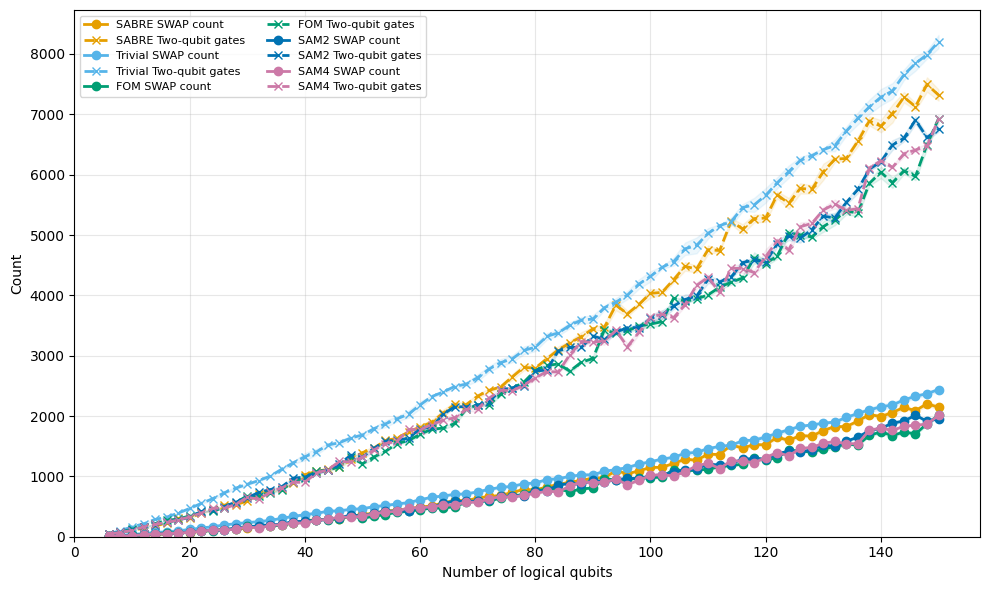

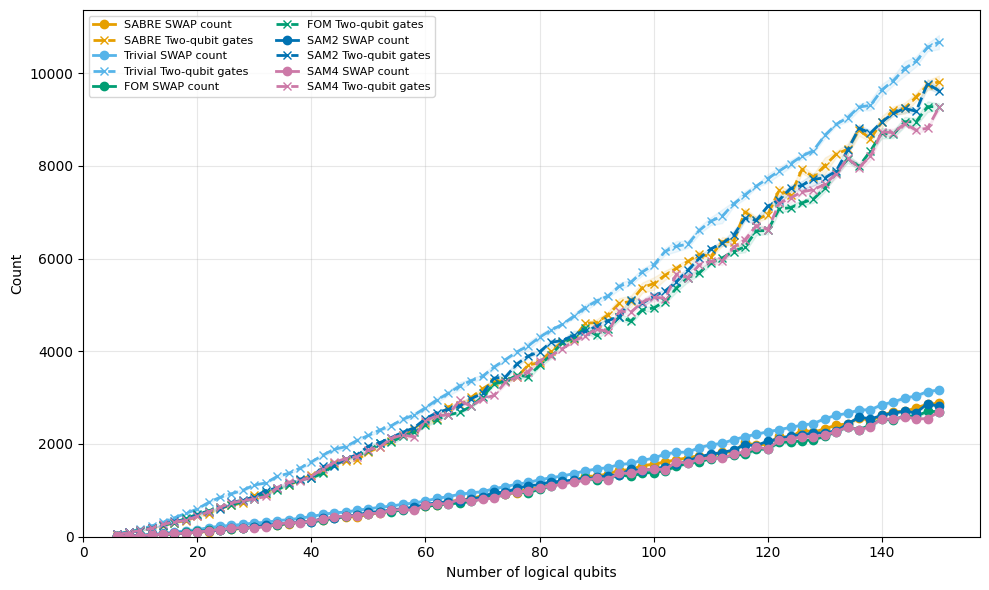

In [5]:
import matplotlib.pyplot as plt
import numpy as np

ops_method_colors = {
    'SABRE': '#E69F00',
    'Trivial': '#56B4E9',
    'FOM': '#009E73',
    'SAM2': '#0072B2',
    'SAM3': '#D55E00',
    'SAM4': '#CC79A7',
    'SAM5': '#F0E442',
}


def plot_swaps_and_two_qubit_gates(results, node_list, params, graph_label):
    """Overlay means for SWAP and optimized two-qubit-gate counts."""
    for param in params:
        if 'swaps' not in results[param] or 'two_qubit_gates' not in results[param]:
            raise KeyError(
                'The saved result is missing swaps or two_qubit_gates. '
                'Recompute the benchmark with return_ops_all_methods.'
            )
        methods = list(results[param]['swaps']['means'])
        fig, ax = plt.subplots(figsize=(10, 6))
        for method in methods:
            if method=='SAM3':
                continue
            color = ops_method_colors.get(method)
            for metric, label, linestyle, marker in [
                ('swaps', 'SWAP count', '-', 'o'),
                ('two_qubit_gates', 'Two-qubit gates', '--', 'x'),
            ]:
                stats = results[param][metric]
                means = np.asarray(stats['means'][method], dtype=float)
                stddevs = np.asarray(stats['stddevs'][method], dtype=float)
                ax.plot(
                    node_list, means,
                    color=color, linestyle=linestyle, marker=marker,
                    linewidth=2, label=f'{method} {label}',
                )
                ax.fill_between(
                    node_list,
                    np.maximum(0, means - stddevs),
                    means + stddevs,
                    color=color,
                    alpha=0.10,
                )

        ax.set_xlabel('Number of logical qubits')
        ax.set_ylabel('Count')
        # ax.set_title(f'{graph_label}: SWAPs and two-qubit gates (param = {param})')
        ax.set_xlim(left=0)
        ax.set_ylim(bottom=0)
        ax.grid(alpha=0.3)
        ax.legend(ncol=2, fontsize=8)
        fig.tight_layout()
        plt.show()


plot_swaps_and_two_qubit_gates(
    results_reg, nodes_reg, params_reg, 'Random regular graphs'
)
plot_swaps_and_two_qubit_gates(
    results_ba, nodes_ba, params_ba, 'Barabasi-Albert graphs'
)
